# Exploratory analysis — structure in the inputs and in the embeddings

A **standalone** notebook. It does not import anything from
`pangenomic_gat_pipeline.ipynb` and does not need the model to have been
trained: it rebuilds every input representation from the raw files, and picks up
learned embeddings only if `results/embeddings.parquet` happens to exist.

### The question it answers

Before asking a model to separate classes, it is worth knowing whether the
classes are separable *at all* in the raw features — and afterwards, whether the
model actually improved on that. So we build several **representations** of the
same (gene, tissue) units and put each one through an identical pipeline:

| representation | where it comes from | dims |
|---|---|---|
| `topology` | PCHi-C graph summary statistics per gene×tissue | ~20 |
| `histone` | mean mark signal over the bait fragment | 2 × n_marks |
| `sequence` | k-mer composition of the promoter window | 4^k |
| `expression` | the gene's TPM profile across tissues | n_tissues |
| `z_seq`, `z_str`, `z` | model embeddings, **if the pipeline has been run** | 128 |

Each gets: PCA (scree + scatter), UMAP and t-SNE, k-selection, three clustering
algorithms, cluster-vs-label agreement, per-class separability, and a linear
probe. The final table ranks representations by how well each class structure
is recoverable.

### What "checking class classification" means here

Two different things, both reported:

1. **Unsupervised** — do clusters found *without* labels line up with the
   labels? Measured by ARI, NMI, homogeneity/completeness/V-measure and cluster
   purity. High values mean the class structure is the dominant variance in the
   data.
2. **Supervised probe** — can a *linear* classifier read the class off the
   representation? Measured by cross-validated per-class precision/recall/F1.
   A representation can fail (1) but pass (2): the class may be linearly
   decodable while some other factor dominates the variance.

The gap between the two is informative, so both are shown side by side.

## 1 · Configuration and environment

Same conda env as the main pipeline (`pangenomic-gat`). This notebook is lighter
— it needs no PyTorch unless you ask it to re-embed — so `torch` is imported
optionally.

`N_SUBSAMPLE` caps how many (gene, tissue) rows go into UMAP, t-SNE and
clustering. t-SNE is O(n²)-ish and silhouette scores are O(n²) in memory, so
8,000 is a sensible ceiling; PCA and the linear probe run on everything.

In [1]:
from pathlib import Path
import os, sys, json, math, time, warnings, itertools
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import scipy.stats as sstats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_completeness_v_measure, silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score, confusion_matrix,
    classification_report, precision_recall_fscore_support, accuracy_score,
    balanced_accuracy_score, roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- paths
def _find_project_root(start: Path) -> Path:
    """Notebooks live in notebooks/, one level below the repo root, so
    Path.cwd() (Jupyter sets it to the notebook's own directory) is no
    longer the project root by itself. Walk upward for the marker that
    identifies the root instead of assuming a fixed number of parent hops."""
    for p in (start, *start.parents):
        if (p / "setup_env.sh").exists():
            return p
    return start

PROJECT_ROOT = Path(os.environ.get("PANGENOMIC_ROOT", _find_project_root(Path.cwd()))).resolve()
INTERACT_DIR = PROJECT_ROOT / "interection_data"
HISTONE_DIR  = PROJECT_ROOT / "histone"
RNASEQ_DIR   = PROJECT_ROOT / "rna_seq"
CACHE_DIR    = PROJECT_ROOT / "cache"
RESULTS_DIR  = PROJECT_ROOT / "results"
EDA_DIR      = RESULTS_DIR / "eda"; EDA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR      = EDA_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TPM_FILE     = RNASEQ_DIR / "rnaseq.rsem_genes_tpm.txt"
EMB_FILE     = RESULTS_DIR / "embeddings.parquet"

# ---------------------------------------------------------------- knobs
SEED            = 42
N_TISSUES       = 10        # tissues to load (None = all); keeps the plots readable
MIN_CHICAGO     = 5.0
N_SUBSAMPLE     = 8000      # cap for UMAP / t-SNE / clustering / silhouette
KMER_K          = 4         # promoter k-mer size -> 4**K dims
TPM_THRESHOLD   = 1.0
TAU_THRESHOLD   = 0.85
PCA_COMPONENTS  = 50        # kept before UMAP / t-SNE, standard practice
RUN_TSNE        = True
np.random.seed(SEED)

# ---------------------------------------------------------------- env
print(f"python      : {sys.version.split()[0]}")
print(f"conda env   : {os.environ.get('CONDA_DEFAULT_ENV', '(none)')}")
print(f"project     : {PROJECT_ROOT}")

try:
    import umap
    HAS_UMAP = True
except Exception as e:
    HAS_UMAP = False
    print(f"  umap-learn unavailable ({type(e).__name__}) -> PCA used in its place")

try:
    from sklearn.cluster import HDBSCAN
    HAS_HDBSCAN = True
except ImportError:
    try:
        from hdbscan import HDBSCAN
        HAS_HDBSCAN = True
    except Exception:
        HAS_HDBSCAN = False
if not HAS_HDBSCAN:
    print("  HDBSCAN unavailable -> density clustering skipped")

try:
    import pyBigWig
    HAS_BIGWIG = True
except Exception:
    HAS_BIGWIG = False
    print("  pyBigWig unavailable -> histone representation will be skipped")

# ---------------------------------------------------------------- style
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": ":",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})
PAL = ["#00A38C", "#E08A2E", "#D14A73", "#5B85D6", "#7C6BAD",
       "#4C9A5A", "#C25E5E", "#3F8FA3", "#A8823C", "#8C5B8E"]
sns.set_palette(PAL)
CMAP_SEQ, CMAP_DIV = "viridis", "RdBu_r"

def savefig(fig, name):
    p = FIG_DIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight", facecolor="white")
    print(f"  figure -> {p.relative_to(PROJECT_ROOT)}")

def subsample(n, cap=N_SUBSAMPLE, seed=SEED):
    if n <= cap:
        return np.arange(n)
    return np.sort(np.random.default_rng(seed).choice(n, cap, replace=False))

print(f"\numap={HAS_UMAP}  hdbscan={HAS_HDBSCAN}  bigwig={HAS_BIGWIG}  tsne={RUN_TSNE}")

python      : 3.10.21
conda env   : pangenomic-gat
project     : /home/subhadip/pchic_gat

umap=True  hdbscan=True  bigwig=True  tsne=True


## 2 · Load interactions and build the `topology` representation

One row per **(gene, tissue)**, summarising that promoter's contact profile.
These are hand-built features — the point is to have an interpretable baseline
that any learned embedding has to beat.

| feature | why it might carry class signal |
|---|---|
| `degree` | number of significant contacts; active promoters tend to have more |
| `score_*` | CHiCAGO score distribution — confidence of the contacts |
| `reads_*` | raw support |
| `dist_*` | how far the contacts reach; proximal vs distal regulation |
| `span` | genomic footprint of the whole neighbourhood |
| `frag_len_*` | fragment sizes, a partial proxy for GC/cut-site density |
| `n_partner_genes` | how many other annotated genes it touches |

`degree` and `span` are the two most likely to encode tissue identity trivially
(sequencing depth differs per tissue), so watch whether the clustering ends up
driven by them — the loadings plot in section 8 will say.

In [2]:
def parse_loops(path, sample_id, tissue, min_score):
    df = pd.read_csv(path, sep="\t", dtype=str)
    df["score"] = pd.to_numeric(df["score"], errors="coerce")
    df["N_reads"] = pd.to_numeric(df["N_reads"], errors="coerce")
    df = df[df["score"] >= min_score].copy()
    for side, col in (("bait", "bait_frag"), ("other", "other_frag")):
        parts = df[col].str.split(",", expand=True)
        df[f"{side}_chr"] = parts[0]
        df[f"{side}_start"] = pd.to_numeric(parts[1], errors="coerce")
        df[f"{side}_end"] = pd.to_numeric(parts[2], errors="coerce")
    genes = df["bait_gene"].fillna("").where(df["bait_gene"].fillna("").str.len() > 0,
                                             df["bait_closest_gene"].fillna(""))
    df["gene"] = genes.str.split(",")
    df = df.explode("gene")
    df["gene"] = df["gene"].str.strip()
    df = df[(df["gene"] != "") & df["gene"].notna()]
    df["sample_id"], df["tissue"] = sample_id, tissue
    df["distance"] = ((df["other_start"] + df["other_end"]) / 2
                      - (df["bait_start"] + df["bait_end"]) / 2).abs()
    df["bait_len"] = df["bait_end"] - df["bait_start"]
    df["other_len"] = df["other_end"] - df["other_start"]
    df["n_oe_genes"] = df["oe_gene"].fillna("").apply(
        lambda s: 0 if not s else len([g for g in s.split(",") if g.strip()]))
    return df


files = sorted(INTERACT_DIR.glob("*_merged_loop.txt"))
if not files:
    raise FileNotFoundError(f"no *_merged_loop.txt under {INTERACT_DIR}")
meta_files = []
for p in files:
    stem = p.name.replace("_merged_loop.txt", "")
    sid, _, tname = stem.partition("_")
    meta_files.append((sid, tname, p))
if N_TISSUES:
    meta_files = meta_files[:N_TISSUES]

frames = []
for sid, tname, p in meta_files:
    d = parse_loops(p, sid, tname, MIN_CHICAGO)
    frames.append(d)
    print(f"  {sid} {tname:<38} {len(d):>8,} gene-exploded rows")
loops = pd.concat(frames, ignore_index=True)
del frames
print(f"\ntotal {len(loops):,} rows | {loops.gene.nunique():,} genes | "
      f"{loops.tissue.nunique()} tissues")

# ---------------------------------------------------------------- aggregate
g = loops.groupby(["sample_id", "tissue", "gene"])
TOPO = pd.DataFrame({
    "degree":          g.size(),
    "score_mean":      g["score"].mean(),
    "score_median":    g["score"].median(),
    "score_max":       g["score"].max(),
    "score_std":       g["score"].std().fillna(0),
    "score_sum":       g["score"].sum(),
    "reads_mean":      g["N_reads"].mean(),
    "reads_max":       g["N_reads"].max(),
    "reads_sum":       g["N_reads"].sum(),
    "dist_mean":       g["distance"].mean(),
    "dist_median":     g["distance"].median(),
    "dist_max":        g["distance"].max(),
    "dist_min":        g["distance"].min(),
    "dist_std":        g["distance"].std().fillna(0),
    "span":            g["other_end"].max() - g["other_start"].min(),
    "bait_len":        g["bait_len"].first(),
    "frag_len_mean":   g["other_len"].mean(),
    "frag_len_std":    g["other_len"].std().fillna(0),
    "n_partner_genes": g["n_oe_genes"].sum(),
}).reset_index()

# heavy-tailed columns -> log1p so PCA is not dominated by a few outliers
LOG_COLS = ["score_sum", "reads_mean", "reads_max", "reads_sum", "dist_mean",
            "dist_median", "dist_max", "dist_min", "dist_std", "span",
            "bait_len", "frag_len_mean", "frag_len_std", "degree",
            "n_partner_genes"]
for c in LOG_COLS:
    TOPO[c] = np.log1p(TOPO[c].clip(lower=0).fillna(0))
TOPO = TOPO.fillna(0)

KEYS = ["sample_id", "tissue", "gene"]
TOPO_COLS = [c for c in TOPO.columns if c not in KEYS]
print(f"\ntopology matrix: {TOPO.shape[0]:,} (gene, tissue) rows x {len(TOPO_COLS)} features")
print(TOPO[TOPO_COLS].describe().T[["mean", "std", "min", "max"]].round(2).to_string())

  0002 Embryo - Trophoblast                     13,190 gene-exploded rows
  0003 Spleen                                    8,691 gene-exploded rows
  0004 Small Intestine - Terminal Ileum            936 gene-exploded rows
  0008 Muscle - Skeletal                           913 gene-exploded rows
  0009 Pancreas                                  1,235 gene-exploded rows
  0010 Ovary                                       669 gene-exploded rows
  0011 Nerve - Tibial                            1,408 gene-exploded rows
  0012 Embryo - Mesendoderm                      1,040 gene-exploded rows
  0013 Cells - Mesenchymal Stem Cell             5,358 gene-exploded rows
  0014 Blood - Lymphoblast                       2,445 gene-exploded rows

total 35,885 rows | 8,667 genes | 10 tissues

topology matrix: 18,679 (gene, tissue) rows x 19 features
                  mean   std   min     max
degree            0.95  0.42  0.69    3.64
score_mean         inf   NaN  5.00     inf
score_median       inf   N

## 3 · `histone` representation

Mean bigWig signal over each gene's bait fragment, per available mark, plus the
availability mask. Marks the pipeline could not find for a tissue stay at zero
with mask 0 — the same convention as the main notebook, so a zero here always
means "not measured" rather than "measured as zero".

If `pyBigWig` is missing or no tracks are present, this representation is
skipped and everything downstream adapts.

In [3]:
MARKS = ["H3K4me1", "H3K4me3", "H3K27ac", "H3K27me3", "H3K36me3", "H3K9me3", "CTCF"]
import re
mark_re = re.compile(
    r"^(?P<sid>\d+)\.(?P<mark>.+?)(?:\s*\(\d+\))?(?:\.(?P<asm>GRCh38|hg38|hg19))?\.bw$")

hist_map = defaultdict(lambda: defaultdict(list))
for p in sorted(HISTONE_DIR.glob("*.bw")):
    m = mark_re.match(p.name)
    if m:
        hist_map[m.group("sid")][m.group("mark")].append(p)

HIST = None
if HAS_BIGWIG and hist_map:
    sids = sorted({s for s, _, _ in meta_files} & set(hist_map))
    print(f"histone tracks for {len(sids)} of {len(meta_files)} loaded tissues")
    if sids:
        bait = (loops.groupby(["sample_id", "tissue", "gene"])
                     .agg(chrom=("bait_chr", "first"), start=("bait_start", "first"),
                          end=("bait_end", "first")).reset_index())
        handles, rows = {}, []
        for sid in sids:
            for mk in MARKS:
                for p in hist_map[sid].get(mk, []):
                    try:
                        handles[(sid, mk)] = pyBigWig.open(str(p)); break
                    except Exception:
                        pass
        sub = bait[bait.sample_id.isin(sids)].reset_index(drop=True)
        vals = np.zeros((len(sub), len(MARKS)), dtype=np.float32)
        for i, r in enumerate(sub.itertuples(index=False)):
            for j, mk in enumerate(MARKS):
                bw = handles.get((r.sample_id, mk))
                if bw is None:
                    continue
                try:
                    ch = r.chrom if r.chrom in bw.chroms() else r.chrom.replace("chr", "")
                    if ch not in bw.chroms():
                        continue
                    s, e = int(r.start), min(int(r.end), bw.chroms()[ch])
                    v = bw.stats(ch, max(0, s), e, type="mean")[0]
                    if v is not None and np.isfinite(v):
                        vals[i, j] = float(v)
                except Exception:
                    pass
            if i % 20000 == 0 and i:
                print(f"    {i:,}/{len(sub):,}")
        for bw in handles.values():
            try: bw.close()
            except Exception: pass

        HIST = sub[KEYS].copy()
        for j, mk in enumerate(MARKS):
            HIST[mk] = np.log1p(np.clip(vals[:, j], 0, None))
        for mk in MARKS:
            HIST[f"mask:{mk}"] = HIST.apply(
                lambda r, m=mk: float((r["sample_id"], m) in handles), axis=1)
        HIST_COLS = [c for c in HIST.columns if c not in KEYS]
        print(f"\nhistone matrix: {HIST.shape[0]:,} rows x {len(HIST_COLS)} features")
        present = [m for m in MARKS if HIST[m].std() > 0]
        print(f"  marks with non-zero variance: {present}")
        if present:
            print(HIST[present].describe().T[["mean", "std", "max"]].round(3).to_string())
    else:
        print("  none of the loaded tissues have histone tracks")
else:
    print("histone representation skipped "
          f"(pyBigWig={HAS_BIGWIG}, tracks={len(hist_map)})")

histone representation skipped (pyBigWig=True, tracks=0)


## 4 · `sequence` representation — promoter k-mer composition

Rather than re-extracting sequence from the 2bit (slow, and it needs the genome
downloaded), we reuse the one-hot cache the main pipeline writes to
`cache/promoter_onehot_*.npz` and convert each promoter to a **k-mer frequency
vector** (`KMER_K = 4` → 256 dims).

Why k-mers rather than the raw one-hot: PCA on a 4×16384 one-hot is dominated by
positional alignment artefacts, not by composition. k-mer frequencies are
translation-invariant, which is what you want when asking "do promoters of
expressed genes look compositionally different".

This is a deliberately *weak* summary — it throws away all positional
information — so it sets a floor that the Hyena tower's `z_seq` should clear
comfortably. If it does not, the sequence tower is not learning anything a
4-mer count could not.

If no cache exists, the section is skipped with a note on how to create one.

In [4]:
SEQF = None
caches = sorted(CACHE_DIR.glob("promoter_onehot_*.npz"))
if caches:
    cpath = max(caches, key=lambda p: p.stat().st_size)
    z = np.load(cpath, allow_pickle=True)
    seq_genes = [str(g) for g in z["genes"]]
    onehot = z["onehot"]                       # (n_genes, 4, L) uint8
    print(f"loaded {cpath.name}: {onehot.shape}")

    K = KMER_K
    n_kmers = 4 ** K
    idx = np.argmax(onehot, axis=1).astype(np.int64)        # (n, L) base index
    valid = onehot.sum(axis=1) > 0                          # False where N
    n, L = idx.shape
    counts = np.zeros((n, n_kmers), dtype=np.float32)
    # rolling base-4 encode; positions containing an N are dropped
    codes = np.zeros((n, L - K + 1), dtype=np.int64)
    ok = np.ones((n, L - K + 1), dtype=bool)
    for j in range(K):
        codes = codes * 4 + idx[:, j:L - K + 1 + j]
        ok &= valid[:, j:L - K + 1 + j]
    for i in range(n):
        c = codes[i][ok[i]]
        if len(c):
            counts[i] = np.bincount(c, minlength=n_kmers)
    counts /= np.clip(counts.sum(1, keepdims=True), 1, None)   # frequencies

    kmer_names = ["".join(p) for p in itertools.product("ACGT", repeat=K)]
    SEQF = pd.DataFrame(counts, columns=kmer_names)
    SEQF.insert(0, "gene", seq_genes)
    SEQ_COLS = kmer_names
    print(f"\nk-mer matrix: {SEQF.shape[0]:,} genes x {len(SEQ_COLS)} {K}-mers")

    gc = (onehot[:, 1, :] + onehot[:, 2, :]).sum(1) / L
    cpg = SEQF["CG" + "A" * (K - 2)].values if K > 2 else None
    print(f"  mean GC = {gc.mean():.3f}   (promoters should be well above 0.41)")
    top = SEQF[SEQ_COLS].mean().sort_values(ascending=False)
    print(f"  most frequent {K}-mers: "
          + ", ".join(f"{k}={v:.4f}" for k, v in top.head(6).items()))
    print(f"  least frequent          : "
          + ", ".join(f"{k}={v:.4f}" for k, v in top.tail(4).items()))
    obs_cg = SEQF[[c for c in SEQ_COLS if "CG" in c]].sum(1).mean()
    print(f"  fraction of {K}-mers containing CpG: {obs_cg:.4f}  "
          "(CpG islands are the classic promoter signature)")
else:
    print("no cache/promoter_onehot_*.npz found.")
    print("Run the main pipeline through its sequence cell once, or set")
    print("N_TISSUES small and run it in fast_mode; the cache is reused here.")

no cache/promoter_onehot_*.npz found.
Run the main pipeline through its sequence cell once, or set
N_TISSUES small and run it in fast_mode; the cache is reused here.


## 5 · Labels: the classes we will try to recover

Three class variables, all derived exactly as the main pipeline derives them so
the numbers are comparable:

- **tissue** (multiclass) — which tissue this row came from.
- **expressed** (binary) — gene TPM > 1 in that tissue.
- **tau class** (binary) — Yanai's tau > 0.85, i.e. tissue-restricted vs
  housekeeping. Constant per gene, which matters for interpretation: any
  representation that encodes gene identity will look good on this.

We also keep a continuous **log-TPM** for colouring scatterplots, because a
continuous gradient across an embedding is often more revealing than a
two-colour split.

TPM: 8,488 genes x 43 tissues

label coverage over 18,679 rows
  tissue      : 10 classes
  expressed   : 85.0% labelled, 55.7% positive
  tau class   : 97.0% labelled, 31.4% restricted

                                     n  expressed_rate  median_log_tpm
tissue_class                                                          
Blood - Lymphoblast               1394             NaN           0.000
Cells - Mesenchymal Stem Cell     2513           0.606           2.157
Embryo - Mesendoderm               813           0.539           1.263
Embryo - Trophoblast              6058           0.592           2.002
Muscle - Skeletal                  759           0.572           1.579
Nerve - Tibial                     993           0.498           0.824
Ovary                              593           0.566           1.484
Pancreas                          1058             NaN           0.000
Small Intestine - Terminal Ileum   784           0.248           0.082
Spleen                          

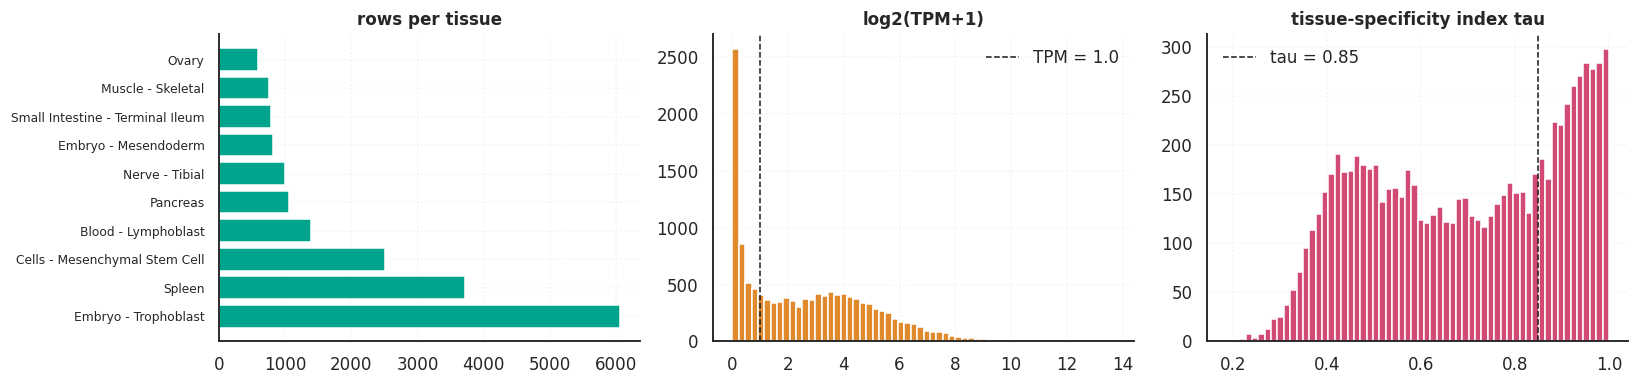

In [5]:
tpm_head = pd.read_csv(TPM_FILE, sep="\t", nrows=0)
rna_cols = [c for c in tpm_head.columns if c not in ("gene_id", "gene_name")]
rna_by_tissue = defaultdict(list)
for c in rna_cols:
    rna_by_tissue[c.split("_")[0]].append(c)

need_genes = set(TOPO["gene"])
tpm = pd.read_csv(TPM_FILE, sep="\t", usecols=["gene_name"] + rna_cols, low_memory=False)
tpm = tpm[tpm.gene_name.isin(need_genes)].groupby("gene_name").max()
TPM = pd.DataFrame({sid: tpm[[c for c in cols if c in tpm.columns]].mean(axis=1)
                    for sid, cols in rna_by_tissue.items()
                    if any(c in tpm.columns for c in cols)})
print(f"TPM: {TPM.shape[0]:,} genes x {TPM.shape[1]} tissues")

logtpm = np.log2(TPM + 1)
mx = logtpm.max(axis=1)
tau = pd.Series(np.nan, index=TPM.index)
ok = mx > 0
tau[ok] = (1 - logtpm[ok].div(mx[ok], axis=0)).sum(axis=1) / (logtpm.shape[1] - 1)

LAB = TOPO[KEYS].copy()
LAB["tissue_class"] = LAB["tissue"]
def lookup(row):
    g, s = row["gene"], row["sample_id"]
    v = TPM.at[g, s] if (g in TPM.index and s in TPM.columns) else np.nan
    return v
LAB["tpm"] = TOPO.apply(lookup, axis=1)
LAB["log_tpm"] = np.log2(LAB["tpm"].fillna(0) + 1)
LAB["expressed"] = np.where(LAB["tpm"].isna(), -1,
                            (LAB["tpm"] > TPM_THRESHOLD).astype(int))
LAB["tau"] = LAB["gene"].map(tau)
LAB["tau_class"] = np.where(LAB["tau"].isna(), -1,
                            (LAB["tau"] > TAU_THRESHOLD).astype(int))

print(f"\nlabel coverage over {len(LAB):,} rows")
print(f"  tissue      : {LAB.tissue_class.nunique()} classes")
print(f"  expressed   : {(LAB.expressed >= 0).mean():.1%} labelled, "
      f"{LAB.loc[LAB.expressed >= 0, 'expressed'].mean():.1%} positive")
print(f"  tau class   : {(LAB.tau_class >= 0).mean():.1%} labelled, "
      f"{LAB.loc[LAB.tau_class >= 0, 'tau_class'].mean():.1%} restricted")
print()
print(LAB.groupby("tissue_class").agg(
    n=("gene", "size"),
    expressed_rate=("expressed", lambda s: s[s >= 0].mean()),
    median_log_tpm=("log_tpm", "median")).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
cnt = LAB.tissue_class.value_counts()
ax[0].barh(cnt.index, cnt.values, color=PAL[0]); ax[0].set_title("rows per tissue")
ax[0].tick_params(axis="y", labelsize=8)
ax[1].hist(LAB.loc[LAB.log_tpm > 0, "log_tpm"], bins=60, color=PAL[1])
ax[1].axvline(np.log2(TPM_THRESHOLD + 1), ls="--", c="k", lw=1,
              label=f"TPM = {TPM_THRESHOLD}")
ax[1].set_title("log2(TPM+1)"); ax[1].legend()
ax[2].hist(tau.dropna(), bins=60, color=PAL[2])
ax[2].axvline(TAU_THRESHOLD, ls="--", c="k", lw=1, label=f"tau = {TAU_THRESHOLD}")
ax[2].set_title("tissue-specificity index tau"); ax[2].legend()
fig.tight_layout(); savefig(fig, "eda_01_labels"); plt.show()

## 6 · Assemble the representations

Every representation is aligned to the same (gene, tissue) key so all downstream
comparisons are on identical rows. Representations defined per *gene* only
(`sequence`, and the model's `z_seq`) are broadcast across that gene's tissues —
which is itself informative: a per-gene representation can never separate
tissues, and the plots will show exactly that.

Features are standardised before PCA. That matters here because the topology
features are on wildly different scales (a log-distance around 5, a CHiCAGO
score around 8, a degree around 2) and unstandardised PCA would just rank them
by variance.

In [6]:
REPS = {}

def register(name, df, cols, per_gene=False, note=""):
    if df is None or not len(cols):
        print(f"  skip  {name:<12} (unavailable)")
        return
    if per_gene:
        merged = TOPO[KEYS].merge(df[["gene"] + cols], on="gene", how="left")
    else:
        merged = TOPO[KEYS].merge(df[KEYS + cols], on=KEYS, how="left")
    X = merged[cols].astype(np.float32).values
    keep = ~np.all(np.isnan(X), axis=1)
    X = np.nan_to_num(X)
    Xs = StandardScaler().fit_transform(X)
    REPS[name] = {"X": Xs, "cols": list(cols), "valid": keep,
                  "per_gene": per_gene, "note": note}
    print(f"  ok    {name:<12} {X.shape}  "
          f"{'per-gene (broadcast)' if per_gene else 'per gene x tissue'}  "
          f"{keep.sum():,} rows with data")

print("input representations")
register("topology", TOPO, TOPO_COLS, note="PCHi-C graph summary statistics")
if HIST is not None:
    register("histone", HIST, HIST_COLS, note="mean mark signal over the bait")
if SEQF is not None:
    register("sequence", SEQF, SEQ_COLS, per_gene=True,
             note=f"{KMER_K}-mer composition of the promoter window")

expr_cols = [c for c in TPM.columns]
EXPR = TPM.copy(); EXPR.insert(0, "gene", EXPR.index)
EXPR[expr_cols] = np.log2(EXPR[expr_cols] + 1)
register("expression", EXPR.reset_index(drop=True), expr_cols, per_gene=True,
         note="the gene's log-TPM profile across tissues")

# combined input view
common = [n for n in ("topology", "histone") if n in REPS]
if len(common) > 1:
    Xc = np.hstack([REPS[n]["X"] for n in common])
    REPS["input_all"] = {"X": Xc,
                         "cols": sum([REPS[n]["cols"] for n in common], []),
                         "valid": np.ones(len(Xc), bool), "per_gene": False,
                         "note": "topology + histone concatenated"}
    print(f"  ok    {'input_all':<12} {Xc.shape}  concatenation of {common}")

print(f"\n{len(REPS)} representations, all aligned to {len(TOPO):,} "
      f"(gene, tissue) rows")

input representations
  ok    topology     (18679, 19)  per gene x tissue  18,679 rows with data
  ok    expression   (18679, 43)  per-gene (broadcast)  18,280 rows with data

2 representations, all aligned to 18,679 (gene, tissue) rows


## 7 · Model embeddings (optional)

If `results/embeddings.parquet` exists — written by the main pipeline's export
cell — its `z`, `z_seq` and `z_str` blocks are joined in on (gene, tissue) and
treated as three more representations.

They are only defined on the **last fold's test split**, so they cover a subset
of rows. Every comparison below is therefore computed on whatever rows each
representation actually has, and the row count is reported alongside each score
so you can see when a number rests on fewer examples.

If the file is absent, this notebook still runs end to end on inputs alone.

In [7]:
HAS_EMB = EMB_FILE.exists()
if HAS_EMB:
    emb = pd.read_parquet(EMB_FILE)
    print(f"loaded {EMB_FILE.name}: {emb.shape}")
    for block in ("z", "z_seq", "z_str"):
        cols = [c for c in emb.columns if c.startswith(f"{block}_")]
        if not cols:
            continue
        merged = TOPO[KEYS].merge(emb[["gene", "tissue"] + cols].drop_duplicates(
            subset=["gene", "tissue"]), on=["gene", "tissue"], how="left")
        X = merged[cols].values.astype(np.float32)
        keep = ~np.all(np.isnan(X), axis=1)
        if keep.sum() < 50:
            print(f"  skip  {block}: only {keep.sum()} matching rows")
            continue
        Xs = np.zeros_like(X)
        Xs[keep] = StandardScaler().fit_transform(np.nan_to_num(X[keep]))
        REPS[block] = {"X": Xs, "cols": cols, "valid": keep, "per_gene": False,
                       "note": f"learned embedding ({len(cols)}-d)"}
        print(f"  ok    {block:<12} {X.shape}  {keep.sum():,} rows matched")
else:
    print(f"{EMB_FILE} not found - input representations only.")
    print("Run the main pipeline's export cell to produce it, then re-run this notebook.")

SUMMARY = pd.DataFrame([
    {"representation": k, "dims": v["X"].shape[1],
     "rows with data": int(v["valid"].sum()),
     "granularity": "per gene" if v["per_gene"] else "per gene x tissue",
     "source": "learned" if k in ("z", "z_seq", "z_str") else "input",
     "note": v["note"]}
    for k, v in REPS.items()])
print()
print(SUMMARY.to_string(index=False))
SUMMARY.to_csv(EDA_DIR / "representations.csv", index=False)

/home/subhadip/pchic_gat/results/embeddings.parquet not found - input representations only.
Run the main pipeline's export cell to produce it, then re-run this notebook.

representation  dims  rows with data       granularity source                                      note
      topology    19           18679 per gene x tissue  input           PCHi-C graph summary statistics
    expression    43           18280          per gene  input the gene's log-TPM profile across tissues


## 8 · PCA — how much structure, and along which axes

For each representation: the scree curve (variance per component and cumulative)
and, for the input views, the loadings of PC1–PC2 so we can name what the
dominant axis actually is.

**What to look for.** A representation whose first two components carry most of
the variance is essentially low-dimensional; one where variance is spread flat
across 50 components has either rich structure or a lot of noise, and the
clustering results below discriminate between those two cases.

The loadings plot is the honest check on the topology features: if PC1 loads
almost entirely on `degree`, `reads_sum` and `span`, the dominant axis is
**sequencing depth**, not biology, and any tissue clustering that follows is a
batch effect.

  figure -> results/eda/figures/eda_02_pca_scree.png


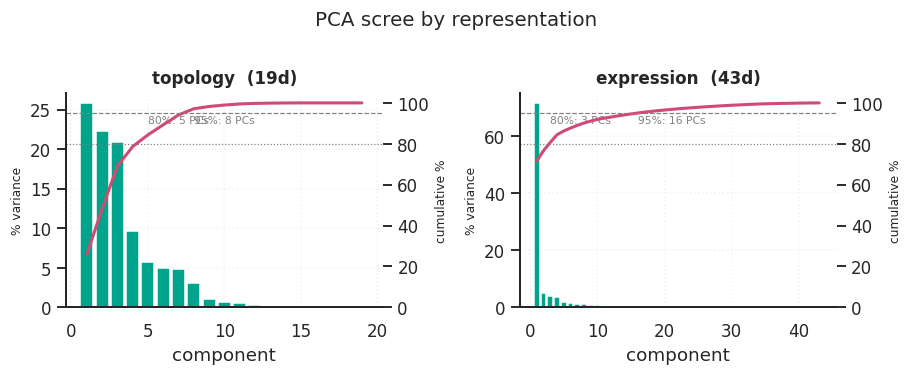

representation  dims     PC1 %   PC1-2 %  PCs for 80%  PCs for 95%  effective dim
      topology    19 25.799999 48.099998            5            8            7.0
    expression    43 71.699997 76.699997            3           16            4.2

'effective dim' = exp(entropy of the variance spectrum): 1 means one
dominant axis, and a value near the full dimensionality means isotropic.
  figure -> results/eda/figures/eda_03_pca_loadings.png


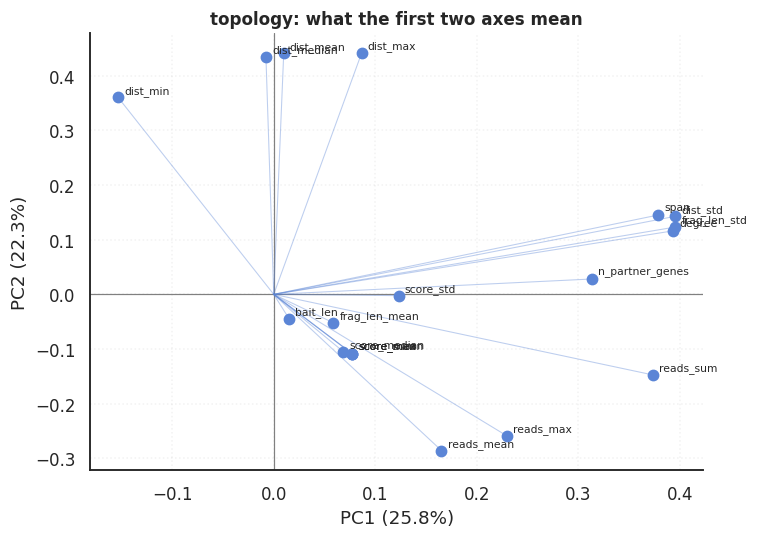


topology PC1 is dominated by: frag_len_std (0.40), dist_std (0.39), degree (0.39), span (0.38), reads_sum (0.37)
  separation along PC1 may be sequencing depth, not biology.


In [8]:
PCAS = {}
for name, R in REPS.items():
    X = R["X"][R["valid"]]
    n_comp = min(PCA_COMPONENTS, X.shape[1], max(X.shape[0] - 1, 2))
    p = PCA(n_components=n_comp, random_state=SEED).fit(X)
    PCAS[name] = {"pca": p, "scores": p.transform(X), "rows": np.where(R["valid"])[0]}

names = list(PCAS)
ncol = min(4, len(names)); nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.3 * nrow), squeeze=False)
for ax, name in zip(axes.ravel(), names):
    ev = PCAS[name]["pca"].explained_variance_ratio_
    ax.bar(np.arange(1, len(ev) + 1), ev * 100, color=PAL[0], width=.85)
    ax2 = ax.twinx()
    ax2.plot(np.arange(1, len(ev) + 1), np.cumsum(ev) * 100, color=PAL[2], lw=2)
    ax2.set_ylim(0, 105); ax2.grid(False); ax2.set_ylabel("cumulative %", fontsize=8)
    for thr, ls in ((80, ":"), (95, "--")):
        k = int(np.searchsorted(np.cumsum(ev) * 100, thr)) + 1
        if k <= len(ev):
            ax2.axhline(thr, ls=ls, c="grey", lw=.8)
            ax.text(k, ev[0] * 100 * .9, f"{thr}%: {k} PCs", fontsize=7, color="grey")
    ax.set_title(f"{name}  ({REPS[name]['X'].shape[1]}d)")
    ax.set_xlabel("component"); ax.set_ylabel("% variance", fontsize=8)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
fig.suptitle("PCA scree by representation", y=1.02, fontsize=13)
fig.tight_layout(); savefig(fig, "eda_02_pca_scree"); plt.show()

rows = []
for name in names:
    ev = PCAS[name]["pca"].explained_variance_ratio_
    cum = np.cumsum(ev)
    rows.append({"representation": name, "dims": REPS[name]["X"].shape[1],
                 "PC1 %": round(ev[0] * 100, 1),
                 "PC1-2 %": round(cum[1] * 100, 1) if len(cum) > 1 else np.nan,
                 "PCs for 80%": int(np.searchsorted(cum, .8)) + 1,
                 "PCs for 95%": int(np.searchsorted(cum, .95)) + 1,
                 "effective dim": round(float(np.exp(sstats.entropy(ev))), 1)})
VAR = pd.DataFrame(rows)
print(VAR.to_string(index=False))
print("\n'effective dim' = exp(entropy of the variance spectrum): 1 means one")
print("dominant axis, and a value near the full dimensionality means isotropic.")
VAR.to_csv(EDA_DIR / "pca_variance.csv", index=False)

# ---- loadings for the interpretable input views -----------------------------
interp = [n for n in ("topology", "histone") if n in PCAS]
if interp:
    fig, axes = plt.subplots(1, len(interp), figsize=(7 * len(interp), 5), squeeze=False)
    for ax, name in zip(axes[0], interp):
        p = PCAS[name]["pca"]
        load = pd.DataFrame(p.components_[:2].T, index=REPS[name]["cols"],
                            columns=["PC1", "PC2"])
        ax.axhline(0, c="grey", lw=.8); ax.axvline(0, c="grey", lw=.8)
        ax.scatter(load.PC1, load.PC2, s=45, color=PAL[3], zorder=3)
        for f, r in load.iterrows():
            ax.annotate(f, (r.PC1, r.PC2), fontsize=7,
                        xytext=(4, 3), textcoords="offset points")
            ax.plot([0, r.PC1], [0, r.PC2], color=PAL[3], lw=.7, alpha=.4)
        ax.set_xlabel(f"PC1 ({p.explained_variance_ratio_[0]*100:.1f}%)")
        ax.set_ylabel(f"PC2 ({p.explained_variance_ratio_[1]*100:.1f}%)")
        ax.set_title(f"{name}: what the first two axes mean")
    fig.tight_layout(); savefig(fig, "eda_03_pca_loadings"); plt.show()

    for name in interp:
        p = PCAS[name]["pca"]
        top = pd.Series(p.components_[0], index=REPS[name]["cols"]).abs().nlargest(5)
        print(f"\n{name} PC1 is dominated by: "
              + ", ".join(f"{k} ({v:.2f})" for k, v in top.items()))
        depthy = {"degree", "reads_sum", "reads_mean", "reads_max", "score_sum", "span"}
        if len(set(top.index) & depthy) >= 3:
            print("  WARNING: PC1 loads mostly on depth-like features. Any tissue")
            print("  separation along PC1 may be sequencing depth, not biology.")

## 9 · PCA scatter, coloured by each class

The same PC1–PC2 plane for every representation, coloured three ways: by tissue,
by expression status, and by continuous log-TPM. Marginal density curves on the
axes make partial separation visible even when the point cloud looks like a
single blob.

Read these as a *lower bound* on separability — PCA is linear and unsupervised,
so failure here does not mean the classes are inseparable, only that they are
not the dominant linear variance.

  figure -> results/eda/figures/eda_04_pca_scatter_topology.png


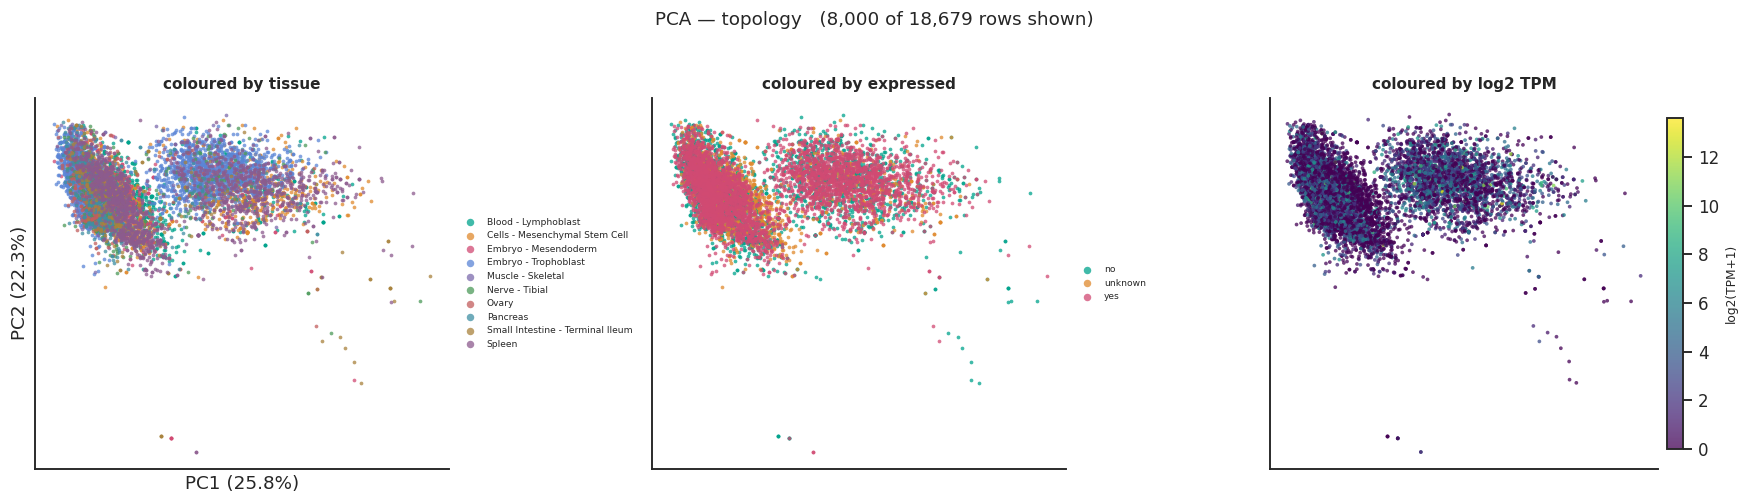

  figure -> results/eda/figures/eda_04_pca_scatter_expression.png


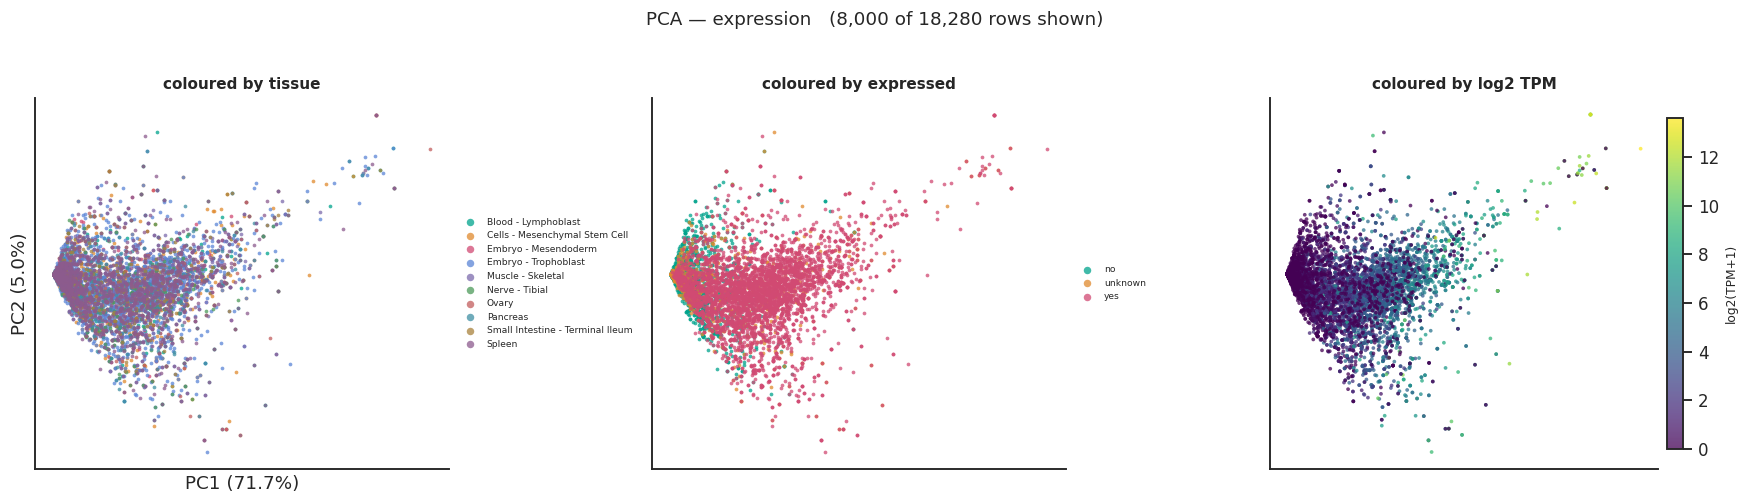

In [9]:
def scatter_panel(ax, xy, colours, title, cmap=None, legend=False,
                  cbar_label=None, s=6):
    if cmap:
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=colours, s=s, cmap=cmap,
                        alpha=.75, linewidths=0, rasterized=True)
        if cbar_label:
            cb = plt.colorbar(sc, ax=ax, fraction=.04, pad=.02)
            cb.set_label(cbar_label, fontsize=8)
    else:
        cats = pd.Categorical(colours)
        for i, lev in enumerate(cats.categories):
            m = cats.codes == i
            ax.scatter(xy[m, 0], xy[m, 1], s=s, alpha=.75, linewidths=0,
                       color=PAL[i % len(PAL)], label=str(lev), rasterized=True)
        if legend:
            ax.legend(fontsize=6, markerscale=2, ncol=1,
                      loc="center left", bbox_to_anchor=(1.01, .5))
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])


COLOURINGS = [
    ("tissue",    lambda L: L["tissue_class"].values, None,      True,  None),
    ("expressed", lambda L: np.where(L["expressed"] < 0, "unknown",
                                     np.where(L["expressed"] == 1, "yes", "no")),
                                                       None,      True,  None),
    ("log2 TPM",  lambda L: L["log_tpm"].values,      CMAP_SEQ,  False, "log2(TPM+1)"),
]

for name in names:
    rows_idx = PCAS[name]["rows"]
    sc = PCAS[name]["scores"]
    sub = subsample(len(sc))
    xy = sc[sub, :2]
    Lsub = LAB.iloc[rows_idx[sub]]
    ev = PCAS[name]["pca"].explained_variance_ratio_

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, (cname, fn, cmap, leg, cbl) in zip(axes, COLOURINGS):
        scatter_panel(ax, xy, fn(Lsub), f"coloured by {cname}", cmap, leg, cbl)
    axes[0].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)")
    axes[0].set_ylabel(f"PC2 ({ev[1]*100:.1f}%)")
    fig.suptitle(f"PCA — {name}   ({len(sub):,} of {len(sc):,} rows shown)",
                 y=1.03, fontsize=12)
    fig.tight_layout(); savefig(fig, f"eda_04_pca_scatter_{name}"); plt.show()

## 10 · UMAP and t-SNE

Non-linear projections of the top `PCA_COMPONENTS` principal components — the
standard pipeline, because feeding raw high-dimensional data to UMAP is slow and
mostly re-discovers the same principal axes anyway.

**A warning that belongs on every one of these plots.** UMAP and t-SNE optimise
*local* neighbourhoods. Distances between well-separated clusters are not
meaningful, cluster sizes are not meaningful, and both will happily produce
visually convincing islands from pure noise. They are for generating hypotheses,
not for testing them — the quantitative sections that follow are the test.

`min_dist` and `n_neighbors` are printed with each plot because the picture
changes substantially with them.

  figure -> results/eda/figures/eda_05_manifold_topology.png


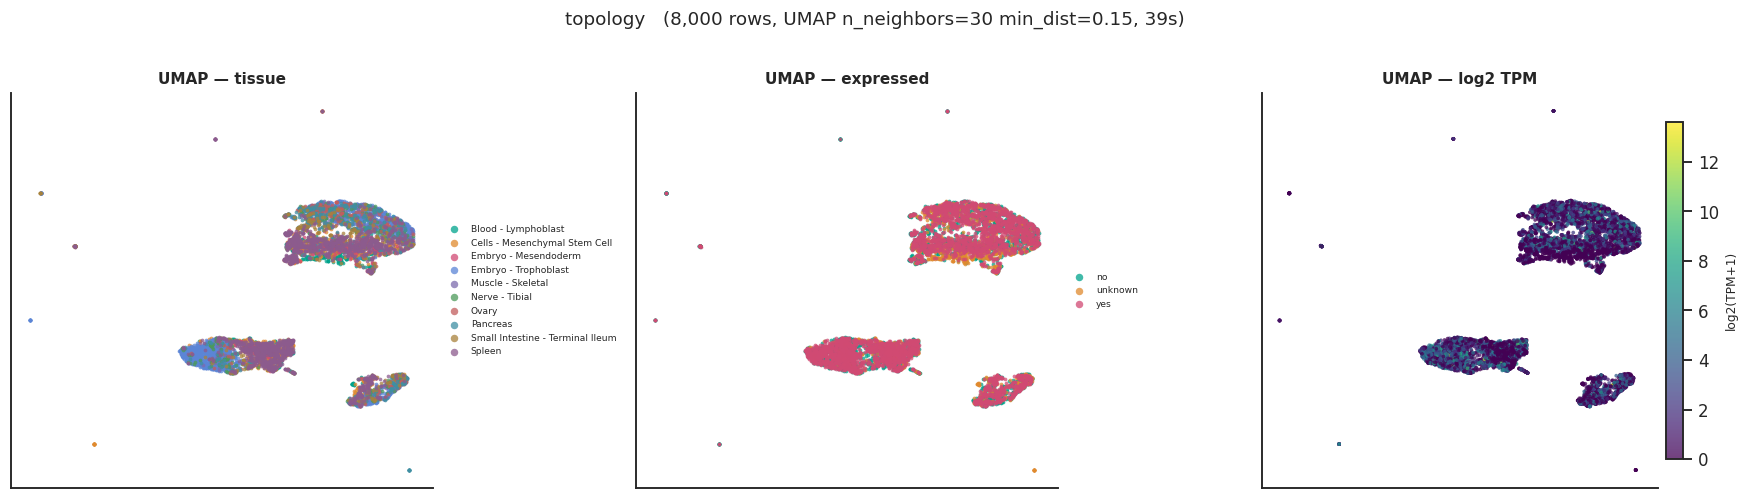

  topology: projected 8,000 rows in 40s
  figure -> results/eda/figures/eda_05_manifold_expression.png


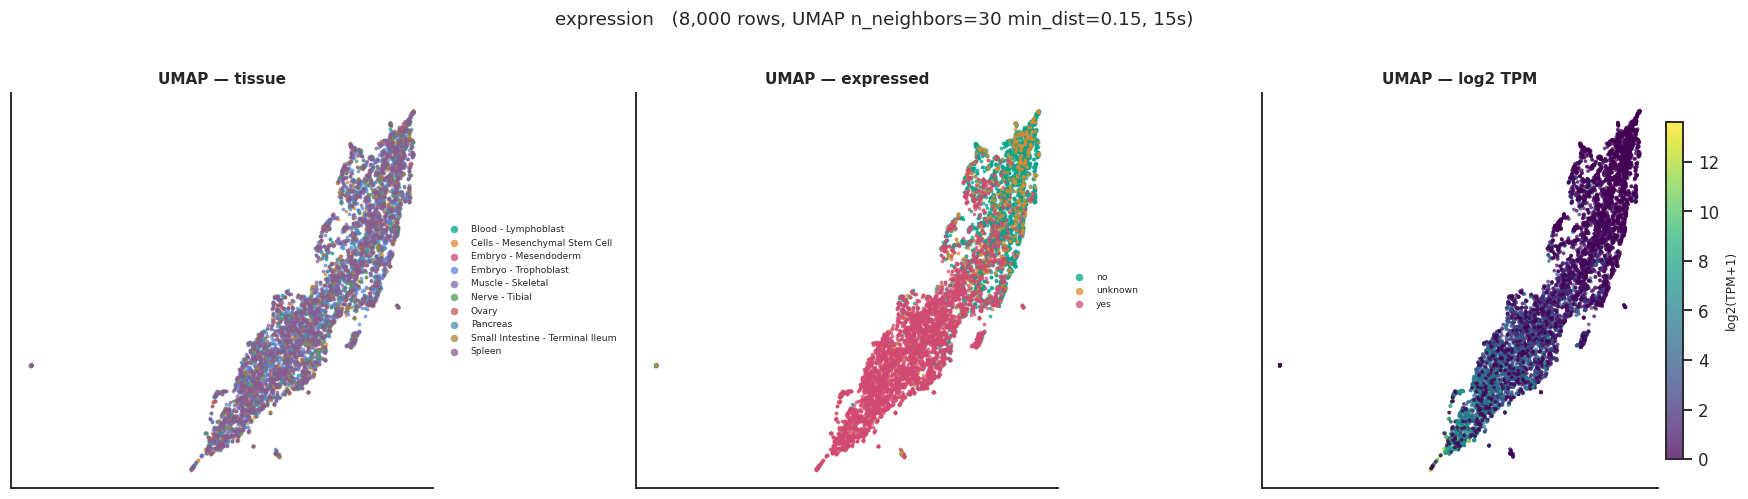

  expression: projected 8,000 rows in 16s


In [10]:
def project(X, method, seed=SEED, n_neighbors=30, min_dist=0.15, perplexity=30):
    if method == "umap" and HAS_UMAP:
        return umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist,
                         random_state=seed, verbose=False).fit_transform(X), "UMAP"
    if method == "tsne":
        return TSNE(n_components=2, perplexity=perplexity, init="pca",
                    random_state=seed, max_iter=750).fit_transform(X), "t-SNE"
    return PCA(n_components=2, random_state=seed).fit_transform(X), "PCA"


UMAP_NN, UMAP_MD, TSNE_PERP = 30, 0.15, 30
EMB2D = {}
for name in names:
    rows_idx = PCAS[name]["rows"]
    sc = PCAS[name]["scores"]
    sub = subsample(len(sc))
    Xp = sc[sub]
    Lsub = LAB.iloc[rows_idx[sub]]
    t0 = time.time()
    u, ulab = project(Xp, "umap", n_neighbors=UMAP_NN, min_dist=UMAP_MD)
    methods = [(u, ulab)]
    if RUN_TSNE and len(Xp) <= 6000:
        methods.append(project(Xp, "tsne", perplexity=TSNE_PERP))
    EMB2D[name] = {"sub": sub, "rows": rows_idx, "umap": u}

    fig, axes = plt.subplots(len(methods), 3, figsize=(16, 4.4 * len(methods)),
                             squeeze=False)
    for r, (xy, mlab) in enumerate(methods):
        for ax, (cname, fn, cmap, leg, cbl) in zip(axes[r], COLOURINGS):
            scatter_panel(ax, xy, fn(Lsub), f"{mlab} — {cname}", cmap, leg, cbl)
    used = [m[1] for m in methods]
    par = ", ".join(
        (f"UMAP n_neighbors={UMAP_NN} min_dist={UMAP_MD}" if u == "UMAP"
         else f"t-SNE perplexity={TSNE_PERP}" if u == "t-SNE"
         else "PCA fallback (umap-learn not installed)") for u in used)
    fig.suptitle(f"{name}   ({len(sub):,} rows, {par}, {time.time()-t0:.0f}s)",
                 y=1.02, fontsize=12)
    fig.tight_layout(); savefig(fig, f"eda_05_manifold_{name}"); plt.show()
    print(f"  {name}: projected {len(sub):,} rows in {time.time()-t0:.0f}s")

## 11 · How many clusters are actually there?

Before running k-means with an arbitrary k, we sweep k and look at three
criteria that disagree in informative ways:

- **inertia (elbow)** — always decreasing; the bend is subjective.
- **silhouette** — peaks at the k with the best-separated clusters. The most
  trustworthy of the three, and the one to weight.
- **Calinski–Harabasz** and **Davies–Bouldin** — variance-ratio and
  compactness/separation criteria; DB is *lower is better*.

A red line marks the true number of tissues. If the silhouette peak is nowhere
near it, the representation does not organise itself by tissue no matter how the
UMAP looked.

  figure -> results/eda/figures/eda_06_k_selection.png


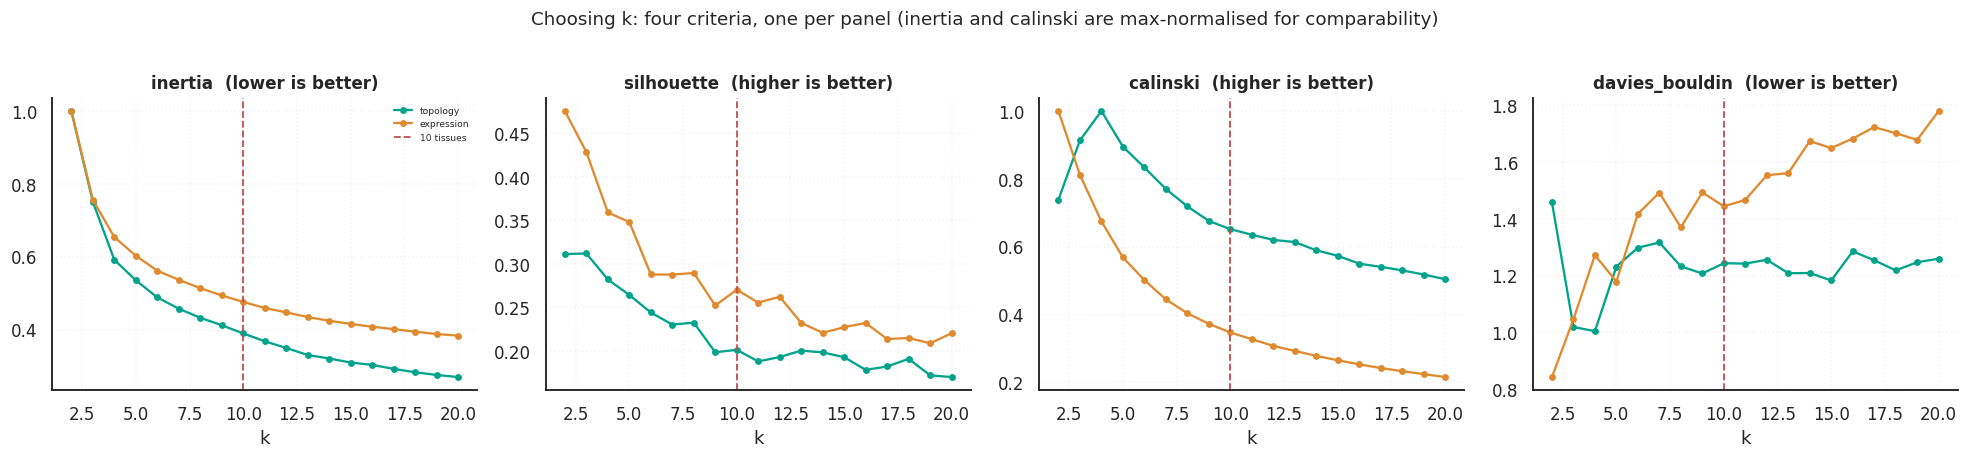

representation  best k (silhouette)  silhouette@best  true n tissues  silhouette@true k
      topology                    3            0.312              10              0.201
    expression                    2            0.476              10              0.270

A best-k far from the tissue count means the strongest grouping in that
representation is something other than tissue.


In [11]:
K_RANGE = list(range(2, min(21, max(3, len(LAB.tissue_class.unique()) * 2 + 1))))
n_true = LAB.tissue_class.nunique()
SWEEP = {}

for name in names:
    sc = PCAS[name]["scores"]
    sub = subsample(len(sc), cap=min(N_SUBSAMPLE, 5000))
    X = sc[sub, :min(20, sc.shape[1])]
    rec = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        lab = km.labels_
        rec.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X, lab) if k > 1 else np.nan,
                    "calinski": calinski_harabasz_score(X, lab),
                    "davies_bouldin": davies_bouldin_score(X, lab)})
    SWEEP[name] = pd.DataFrame(rec)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, (metric, better) in enumerate([("inertia", "lower"), ("silhouette", "higher"),
                                      ("calinski", "higher"),
                                      ("davies_bouldin", "lower")]):
    for j, name in enumerate(names):
        d = SWEEP[name]
        v = d[metric] / d[metric].abs().max() if metric in ("inertia", "calinski") \
            else d[metric]
        axes[i].plot(d.k, v, "o-", ms=3.5, lw=1.5, color=PAL[j % len(PAL)], label=name)
    axes[i].axvline(n_true, ls="--", c="r", lw=1.2,
                    label=f"{n_true} tissues" if i == 0 else None)
    axes[i].set_title(f"{metric}  ({better} is better)")
    axes[i].set_xlabel("k")
    if i == 0:
        axes[i].legend(fontsize=6)
fig.suptitle("Choosing k: four criteria, one per panel "
             "(inertia and calinski are max-normalised for comparability)",
             y=1.03, fontsize=12)
fig.tight_layout(); savefig(fig, "eda_06_k_selection"); plt.show()

best = []
for name in names:
    d = SWEEP[name]
    kb = int(d.loc[d.silhouette.idxmax(), "k"])
    best.append({"representation": name, "best k (silhouette)": kb,
                 "silhouette@best": round(d.silhouette.max(), 3),
                 "true n tissues": n_true,
                 "silhouette@true k": round(
                     float(d.loc[d.k == n_true, "silhouette"].iloc[0])
                     if n_true in d.k.values else np.nan, 3)})
BESTK = pd.DataFrame(best)
print(BESTK.to_string(index=False))
BESTK.to_csv(EDA_DIR / "k_selection.csv", index=False)
print("\nA best-k far from the tissue count means the strongest grouping in that")
print("representation is something other than tissue.")

## 12 · Clustering, and whether the clusters are the classes

Three algorithms per representation, each with a different bias:

- **k-means** — spherical, equal-ish sized clusters.
- **Ward agglomerative** — hierarchical, minimises within-cluster variance.
- **HDBSCAN** — density-based, chooses its own cluster count and, importantly,
  is allowed to label points as **noise**. The noise fraction is reported; a
  very high one means the data has no density structure at the scale examined.

Agreement with the true labels is scored with:

| metric | range | reads as |
|---|---|---|
| ARI | −1…1 | chance-corrected overlap; 0 = random |
| NMI | 0…1 | shared information |
| homogeneity | 0…1 | each cluster contains one class |
| completeness | 0…1 | each class sits in one cluster |
| V-measure | 0…1 | harmonic mean of those two |
| purity | 0…1 | fraction correct if each cluster votes its majority class |

Homogeneity and completeness are worth reading separately: a representation that
splits every tissue into three tight clusters scores high homogeneity and low
completeness, which is a very different failure from mixing tissues together.

Cluster agreement with TISSUE labels

representation     algorithm  n_clusters  noise_frac    ARI   NMI  homogeneity  completeness     V  purity  silhouette
      topology kmeans (k=10)          10       0.000  0.125 0.187        0.191         0.183 0.187   0.444       0.200
      topology   ward (k=10)          10       0.000  0.088 0.158        0.153         0.164 0.158   0.404       0.154
    expression kmeans (k=10)          10       0.000 -0.001 0.004        0.004         0.004 0.004   0.325       0.254
    expression   ward (k=10)          10       0.000 -0.001 0.004        0.004         0.004 0.004   0.324       0.184
      topology       HDBSCAN           2       0.139 -0.022 0.034        0.023         0.071 0.034   0.345       0.338
  figure -> results/eda/figures/eda_07_cluster_agreement.png


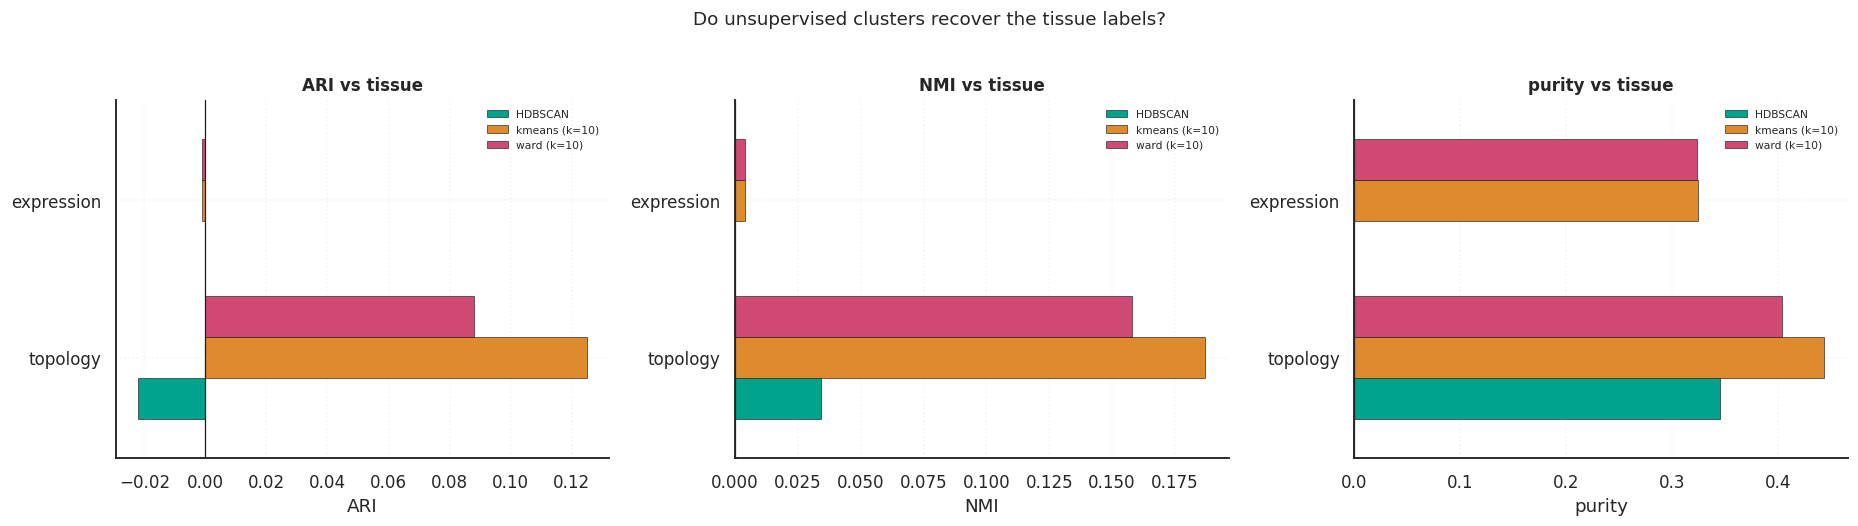

In [12]:
def purity(y_true, y_pred):
    cm = pd.crosstab(y_pred, y_true)
    return cm.max(axis=1).sum() / cm.values.sum()

CLUST = []
ASSIGN = {}
for name in names:
    sc = PCAS[name]["scores"]
    rows_idx = PCAS[name]["rows"]
    sub = subsample(len(sc), cap=min(N_SUBSAMPLE, 6000))
    X = sc[sub, :min(20, sc.shape[1])]
    Lsub = LAB.iloc[rows_idx[sub]]
    y_tis = LabelEncoder().fit_transform(Lsub["tissue_class"])

    algs = {
        f"kmeans (k={n_true})": KMeans(n_clusters=n_true, n_init=10,
                                       random_state=SEED).fit_predict(X),
        f"ward (k={n_true})":   AgglomerativeClustering(
                                    n_clusters=n_true, linkage="ward").fit_predict(X),
    }
    if HAS_HDBSCAN:
        try:
            algs["HDBSCAN"] = HDBSCAN(min_cluster_size=max(20, len(X)//100)
                                      ).fit_predict(X)
        except Exception as e:
            print(f"  {name}: HDBSCAN failed ({type(e).__name__})")

    ASSIGN[name] = {"sub": sub, "rows": rows_idx, "labels": algs, "y_tis": y_tis}
    for alg, lab in algs.items():
        noise = float((lab == -1).mean())
        m = lab != -1
        if m.sum() < 10 or len(np.unique(lab[m])) < 2:
            continue
        h, c, v = homogeneity_completeness_v_measure(y_tis[m], lab[m])
        CLUST.append({
            "representation": name, "algorithm": alg,
            "n_clusters": int(len(np.unique(lab[m]))),
            "noise_frac": round(noise, 3),
            "ARI": round(adjusted_rand_score(y_tis[m], lab[m]), 3),
            "NMI": round(normalized_mutual_info_score(y_tis[m], lab[m]), 3),
            "homogeneity": round(h, 3), "completeness": round(c, 3),
            "V": round(v, 3),
            "purity": round(purity(y_tis[m], lab[m]), 3),
            "silhouette": round(silhouette_score(X[m], lab[m]), 3),
        })

CL = pd.DataFrame(CLUST)
CL.to_csv(EDA_DIR / "clustering_vs_tissue.csv", index=False)
print("Cluster agreement with TISSUE labels\n")
print(CL.sort_values("ARI", ascending=False).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, metric in zip(axes, ["ARI", "NMI", "purity"]):
    piv = CL.pivot_table(index="representation", columns="algorithm", values=metric)
    piv = piv.reindex([n for n in names if n in piv.index])
    piv.plot(kind="barh", ax=ax, width=.78,
             color=PAL[:piv.shape[1]], edgecolor="k", linewidth=.4)
    ax.set_title(f"{metric} vs tissue"); ax.set_xlabel(metric); ax.set_ylabel("")
    ax.legend(fontsize=7); ax.axvline(0, c="k", lw=.8)
fig.suptitle("Do unsupervised clusters recover the tissue labels?",
             y=1.03, fontsize=12)
fig.tight_layout(); savefig(fig, "eda_07_cluster_agreement"); plt.show()

## 13 · Contingency heatmaps

For the strongest representation by ARI: cluster × tissue contingency,
row-normalised so each cluster's composition is visible regardless of its size,
with the rows and columns ordered by hierarchical clustering so any block
structure lines up on the diagonal.

Off-diagonal blocks are the interesting part. Two tissues that consistently land
in one cluster are either biologically similar (the CD4+ subsets, say) or
processed together — and the manifest from the main pipeline will tell you
which.

  figure -> results/eda/figures/eda_08_contingency.png


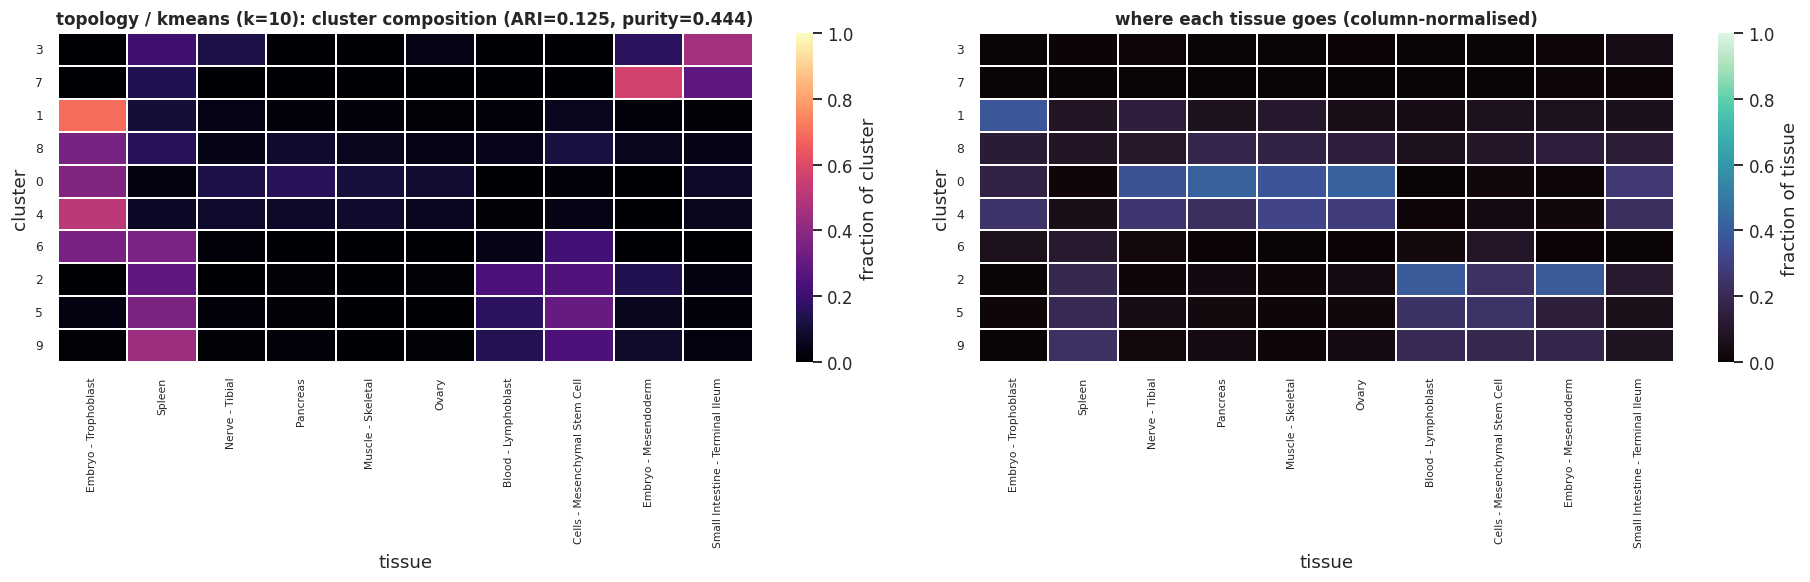


best cluster for each tissue (topology / kmeans (k=10)):
                                  cluster  fraction of tissue in it  cluster purity
tissue                                                                             
Embryo - Trophoblast                    1                     0.381           0.690
Spleen                                  9                     0.233           0.440
Nerve - Tibial                          0                     0.359           0.374
Pancreas                                0                     0.417           0.374
Muscle - Skeletal                       0                     0.374           0.374
Ovary                                   0                     0.418           0.374
Blood - Lymphoblast                     2                     0.396           0.293
Cells - Mesenchymal Stem Cell           5                     0.246           0.363
Embryo - Mesendoderm                    2                     0.397           0.293
Small Intestine - 

In [13]:
if len(CL):
    top = CL.sort_values("ARI", ascending=False).iloc[0]
    tname, talg = top["representation"], top["algorithm"]
    A = ASSIGN[tname]
    lab = A["labels"][talg]
    Lsub = LAB.iloc[A["rows"][A["sub"]]]
    m = lab != -1
    ct = pd.crosstab(pd.Series(lab[m], name="cluster"),
                     pd.Series(Lsub["tissue_class"].values[m], name="tissue"))
    ctn = ct.div(ct.sum(1), axis=0)

    try:
        ro = dendrogram(linkage(ctn.values, "average"), no_plot=True)["leaves"]
        co = dendrogram(linkage(ctn.values.T, "average"), no_plot=True)["leaves"]
        ctn = ctn.iloc[ro, co]; ct = ct.iloc[ro, co]
    except Exception:
        pass

    fig, axes = plt.subplots(1, 2, figsize=(17, 5.4))
    sns.heatmap(ctn, cmap="magma", vmin=0, vmax=1, ax=axes[0],
                cbar_kws={"label": "fraction of cluster"}, linewidths=.3,
                linecolor="white")
    axes[0].set_title(f"{tname} / {talg}: cluster composition "
                      f"(ARI={top['ARI']}, purity={top['purity']})")
    axes[0].tick_params(axis="x", rotation=90, labelsize=7)
    axes[0].tick_params(axis="y", rotation=0, labelsize=8)

    ctt = ct.div(ct.sum(0), axis=1)
    sns.heatmap(ctt, cmap="mako", vmin=0, vmax=1, ax=axes[1],
                cbar_kws={"label": "fraction of tissue"}, linewidths=.3,
                linecolor="white")
    axes[1].set_title("where each tissue goes (column-normalised)")
    axes[1].tick_params(axis="x", rotation=90, labelsize=7)
    axes[1].tick_params(axis="y", rotation=0, labelsize=8)
    fig.tight_layout(); savefig(fig, "eda_08_contingency"); plt.show()

    print(f"\nbest cluster for each tissue ({tname} / {talg}):")
    dom = ctt.idxmax(0).rename("cluster").to_frame()
    dom["fraction of tissue in it"] = ctt.max(0).round(3)
    dom["cluster purity"] = [round(ctn.loc[c].max(), 3) for c in dom["cluster"]]
    print(dom.to_string())

    merged_pairs = (dom.reset_index().groupby("cluster")["tissue"]
                      .apply(list).loc[lambda s: s.str.len() > 1])
    if len(merged_pairs):
        print("\ntissues that share a dominant cluster (check these against the")
        print("histone DOWNLOAD_manifest.csv - shared proxy biosamples show up here):")
        for c, ts in merged_pairs.items():
            print(f"  cluster {c}: {', '.join(ts)}")
else:
    print("no clustering results to display")

## 14 · Per-class separability

Two label-aware, model-free diagnostics computed for every representation and
every class variable:

1. **Silhouette against the true labels.** Not cluster silhouette — this asks
   directly whether points of the same class are closer to each other than to
   other classes. Per-class values are shown as a violin so you can see *which*
   classes are separable rather than only an average.

2. **k-NN neighbourhood purity.** For each point, what fraction of its 20
   nearest neighbours share its label? This is the most direct measure of local
   class structure, and it is what UMAP is implicitly showing you — except
   quantified, and computed in the full space rather than in two dimensions.

A representation with high k-NN purity but near-zero silhouette has classes that
are locally coherent but globally interleaved: perfectly usable by a
non-parametric model, invisible in a PCA plot.

Model-free class separability

--- tissue ---
representation    n  n classes  silhouette  kNN purity  majority baseline  purity lift
      topology 5000         10      -0.056       0.422              0.325        0.097
    expression 5000         10      -0.055       0.187              0.328       -0.141

--- expressed ---
representation    n  n classes  silhouette  kNN purity  majority baseline  purity lift
    expression 4341          2       0.324       0.845              0.544        0.302
      topology 4269          2       0.008       0.524              0.552       -0.028

--- tau class ---
representation    n  n classes  silhouette  kNN purity  majority baseline  purity lift
    expression 4969          2       0.250       0.915              0.680        0.235
      topology 4864          2       0.013       0.583              0.682       -0.099

  figure -> results/eda/figures/eda_09_separability.png


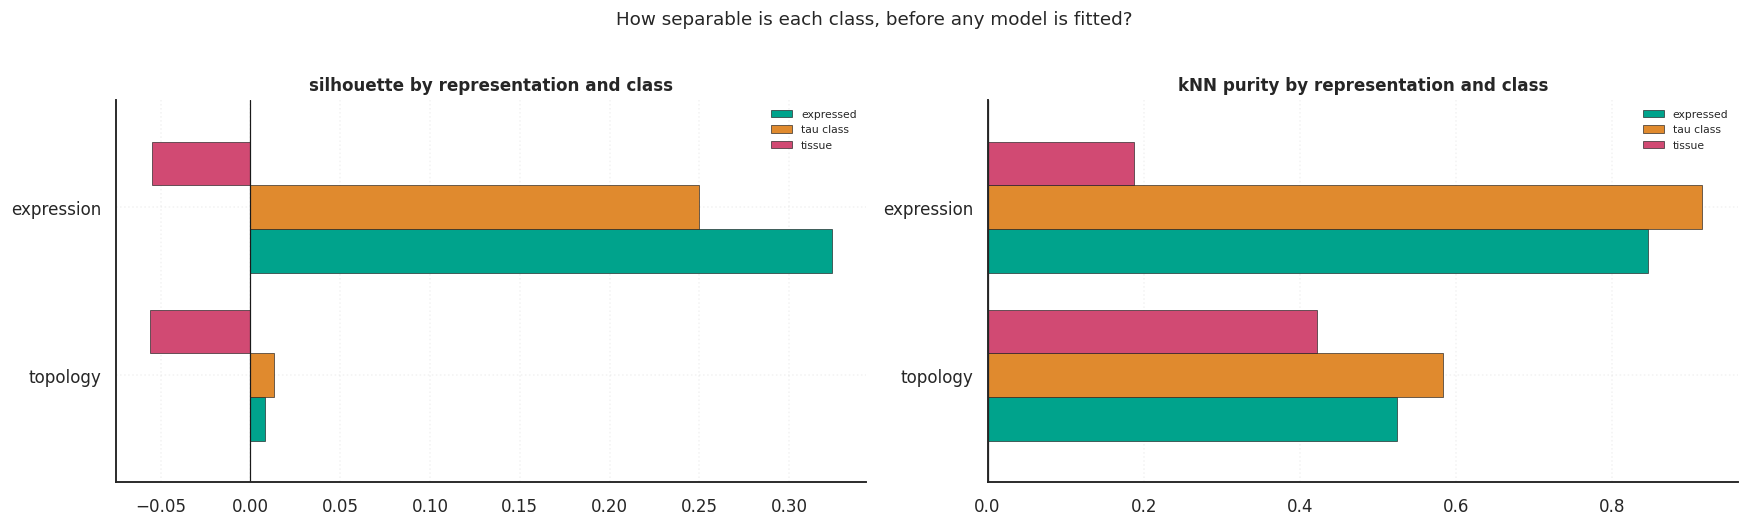

  figure -> results/eda/figures/eda_10_per_class.png


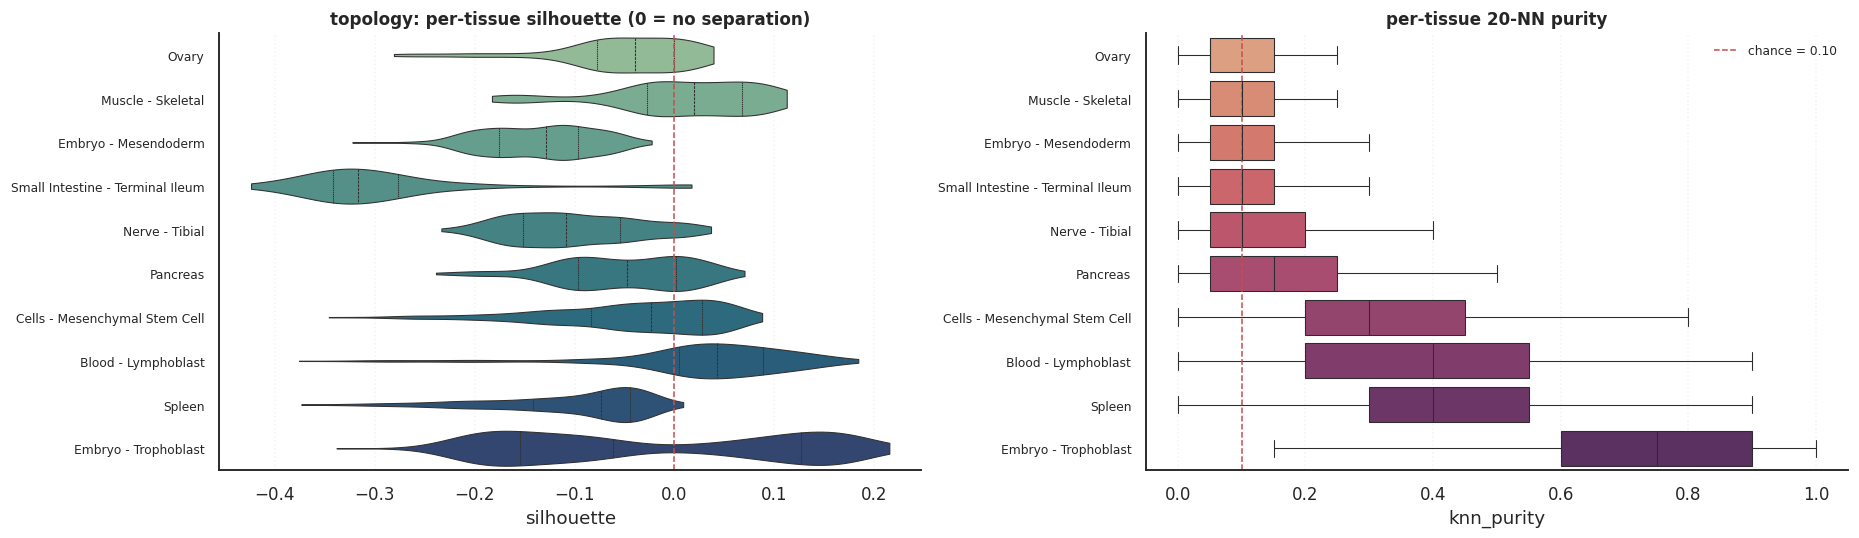


most and least separable tissues in 'topology':
  hardest: Ovary (0.09), Muscle - Skeletal (0.09), Embryo - Mesendoderm (0.12)
  easiest: Blood - Lymphoblast (0.37), Spleen (0.41), Embryo - Trophoblast (0.72)


In [14]:
def knn_purity(X, y, k=20):
    k = min(k, len(X) - 1)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    _, idx = nn.kneighbors(X)
    return (y[idx[:, 1:]] == y[:, None]).mean(axis=1)

CLASS_VARS = [("tissue", "tissue_class"), ("expressed", "expressed"),
              ("tau class", "tau_class")]
SEP = []
PERCLASS_SIL = {}

for name in names:
    sc = PCAS[name]["scores"]
    rows_idx = PCAS[name]["rows"]
    sub = subsample(len(sc), cap=min(N_SUBSAMPLE, 5000))
    X = sc[sub, :min(20, sc.shape[1])]
    Lsub = LAB.iloc[rows_idx[sub]]
    for cname, col in CLASS_VARS:
        y_raw = Lsub[col].values
        m = pd.notna(y_raw) & (y_raw != -1) if col != "tissue_class" else pd.notna(y_raw)
        if m.sum() < 100:
            continue
        y = LabelEncoder().fit_transform(y_raw[m].astype(str))
        if len(np.unique(y)) < 2:
            continue
        Xm = X[m]
        sil = silhouette_samples(Xm, y)
        pur = knn_purity(Xm, y, 20)
        base = pd.Series(y).value_counts(normalize=True).max()
        SEP.append({"representation": name, "class variable": cname,
                    "n": int(m.sum()), "n classes": len(np.unique(y)),
                    "silhouette": round(float(sil.mean()), 3),
                    "kNN purity": round(float(pur.mean()), 3),
                    "majority baseline": round(float(base), 3),
                    "purity lift": round(float(pur.mean() - base), 3)})
        if cname == "tissue":
            PERCLASS_SIL[name] = pd.DataFrame(
                {"class": y_raw[m], "silhouette": sil, "knn_purity": pur})

SEPD = pd.DataFrame(SEP)
SEPD.to_csv(EDA_DIR / "class_separability.csv", index=False)
print("Model-free class separability\n")
for cname, _ in CLASS_VARS:
    d = SEPD[SEPD["class variable"] == cname]
    if len(d):
        print(f"--- {cname} ---")
        print(d.drop(columns="class variable")
               .sort_values("kNN purity", ascending=False).to_string(index=False))
        print()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
for ax, metric in zip(axes, ["silhouette", "kNN purity"]):
    piv = SEPD.pivot_table(index="representation", columns="class variable",
                           values=metric).reindex([n for n in names])
    piv.plot(kind="barh", ax=ax, width=.78, color=PAL[:piv.shape[1]],
             edgecolor="k", linewidth=.4)
    ax.axvline(0, c="k", lw=.8)
    ax.set_title(f"{metric} by representation and class"); ax.set_ylabel("")
    ax.legend(fontsize=7)
fig.suptitle("How separable is each class, before any model is fitted?",
             y=1.03, fontsize=12)
fig.tight_layout(); savefig(fig, "eda_09_separability"); plt.show()

# per-class violins for the best representation
if PERCLASS_SIL:
    bestrep = SEPD[SEPD["class variable"] == "tissue"].sort_values(
        "kNN purity", ascending=False).iloc[0]["representation"]
    d = PERCLASS_SIL[bestrep]
    order = d.groupby("class")["knn_purity"].mean().sort_values().index
    fig, axes = plt.subplots(1, 2, figsize=(17, 5))
    sns.violinplot(data=d, y="class", x="silhouette", order=order, ax=axes[0],
                   inner="quartile", cut=0, linewidth=.7, palette="crest")
    axes[0].axvline(0, c="r", ls="--", lw=1)
    axes[0].set_title(f"{bestrep}: per-tissue silhouette (0 = no separation)")
    sns.boxplot(data=d, y="class", x="knn_purity", order=order, ax=axes[1],
                showfliers=False, linewidth=.7, palette="flare")
    axes[1].axvline(1 / n_true, c="r", ls="--", lw=1, label=f"chance = {1/n_true:.2f}")
    axes[1].set_title("per-tissue 20-NN purity"); axes[1].legend(fontsize=8)
    for a in axes:
        a.tick_params(axis="y", labelsize=8); a.set_ylabel("")
    fig.tight_layout(); savefig(fig, "eda_10_per_class"); plt.show()
    print(f"\nmost and least separable tissues in '{bestrep}':")
    s = d.groupby("class")["knn_purity"].mean().sort_values()
    print("  hardest: " + ", ".join(f"{k} ({v:.2f})" for k, v in s.head(3).items()))
    print("  easiest: " + ", ".join(f"{k} ({v:.2f})" for k, v in s.tail(3).items()))

## 15 · Supervised probe — is the class linearly decodable?

A multinomial logistic regression on each representation, evaluated with
**5-fold cross-validation grouped by gene** — the same grouping the main
pipeline uses, and for the same reason: a gene appears in many tissue rows, and
without grouping the probe would memorise gene identity and report inflated
numbers.

This is deliberately a *linear* probe. The question is not "can something
predict the class" (a big enough model always can) but "is the class already
laid out linearly in this representation". That is the property that makes a
representation useful downstream.

Reported per class variable: accuracy, balanced accuracy, macro F1, and — for
the tissue task — a full per-class precision/recall/F1 table and confusion
matrix. Every score is next to the majority-class baseline, since with 10
tissues and unequal sizes raw accuracy is easy to misread.

Linear probe, gene-grouped 5-fold CV

--- tissue ---
representation    n  classes  accuracy  balanced acc  precision macro  recall macro  F1 macro  majority baseline  lift over baseline
      topology 8000       10     0.564         0.289            0.387         0.289     0.272              0.327               0.238
    expression 8000       10     0.326         0.102            0.085         0.102     0.061              0.329              -0.004

--- expressed ---
representation    n  classes  accuracy  balanced acc  precision macro  recall macro  F1 macro  majority baseline  lift over baseline
    expression 8000        2     0.890         0.891            0.888         0.891     0.889              0.556               0.334
      topology 8000        2     0.571         0.538            0.557         0.538     0.512              0.556               0.014

--- tau class ---
representation    n  classes  accuracy  balanced acc  precision macro  recall macro  F1 macro  majority baselin

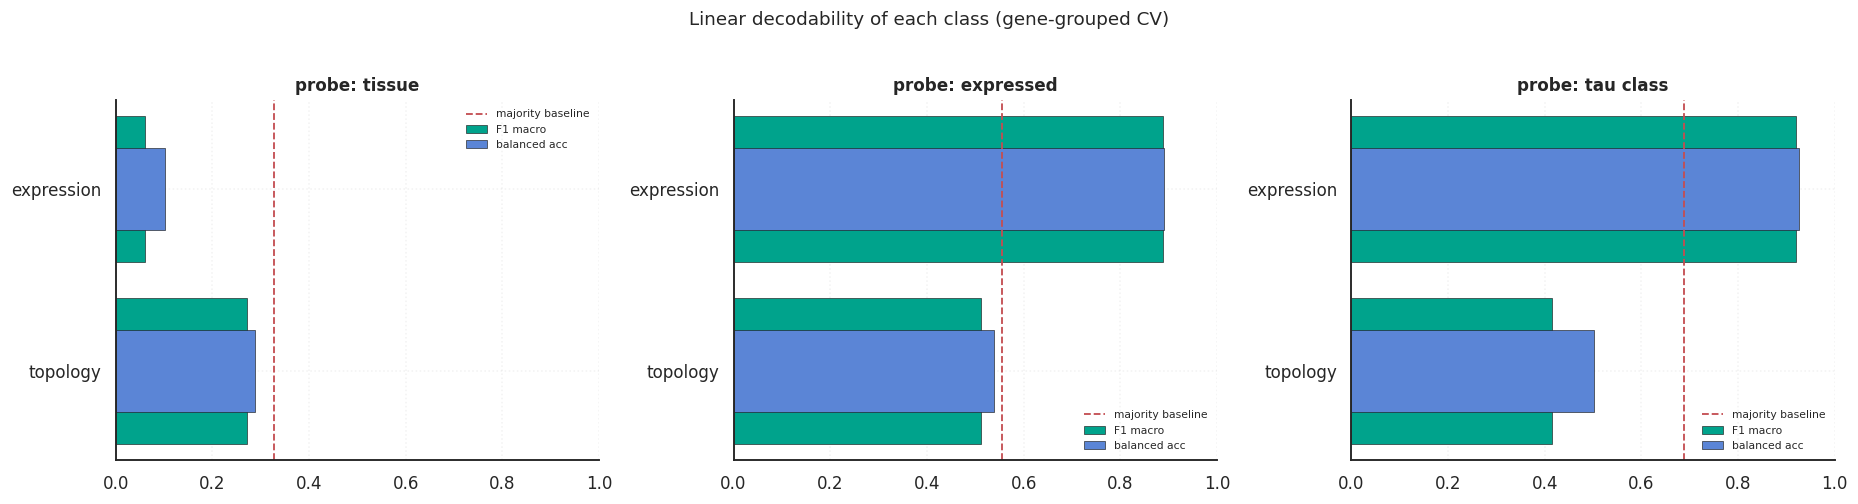

In [15]:
PROBE, PERCLASS = [], {}
for name in names:
    sc = PCAS[name]["scores"]
    rows_idx = PCAS[name]["rows"]
    Xall = sc[:, :min(30, sc.shape[1])]
    Lsub = LAB.iloc[rows_idx]
    for cname, col in CLASS_VARS:
        y_raw = Lsub[col].values
        m = pd.notna(y_raw) if col == "tissue_class" else (
            pd.notna(y_raw) & (y_raw != -1))
        if m.sum() < 200:
            continue
        y = LabelEncoder().fit_transform(y_raw[m].astype(str))
        if len(np.unique(y)) < 2:
            continue
        X = Xall[m]
        groups = Lsub["gene"].values[m]
        cap = subsample(len(X), cap=min(N_SUBSAMPLE, 12000))
        X, y, groups = X[cap], y[cap], groups[cap]
        n_sp = min(5, len(np.unique(groups)))
        if n_sp < 2:
            continue
        clf = LogisticRegression(max_iter=3000, C=1.0, multi_class="auto")
        try:
            pred = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=n_sp),
                                     groups=groups, n_jobs=-1)
        except Exception as e:
            print(f"  {name}/{cname}: probe failed ({type(e).__name__}: {e})")
            continue
        p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro",
                                                     zero_division=0)
        base = pd.Series(y).value_counts(normalize=True).max()
        PROBE.append({"representation": name, "class variable": cname,
                      "n": len(y), "classes": len(np.unique(y)),
                      "accuracy": round(accuracy_score(y, pred), 3),
                      "balanced acc": round(balanced_accuracy_score(y, pred), 3),
                      "precision macro": round(p, 3), "recall macro": round(r, 3),
                      "F1 macro": round(f, 3),
                      "majority baseline": round(base, 3),
                      "lift over baseline": round(accuracy_score(y, pred) - base, 3)})
        if cname == "tissue":
            PERCLASS[name] = (y, pred,
                              LabelEncoder().fit(y_raw[m].astype(str)).classes_)

PRB = pd.DataFrame(PROBE)
PRB.to_csv(EDA_DIR / "linear_probe.csv", index=False)
print("Linear probe, gene-grouped 5-fold CV\n")
for cname, _ in CLASS_VARS:
    d = PRB[PRB["class variable"] == cname]
    if len(d):
        print(f"--- {cname} ---")
        print(d.drop(columns="class variable")
               .sort_values("F1 macro", ascending=False).to_string(index=False))
        print()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (cname, _) in zip(axes, CLASS_VARS):
    d = PRB[PRB["class variable"] == cname].set_index("representation")
    if not len(d):
        ax.axis("off"); continue
    d = d.reindex([n for n in names if n in d.index])
    ax.barh(d.index, d["F1 macro"], color=PAL[0], edgecolor="k", linewidth=.4,
            label="F1 macro")
    ax.barh(d.index, d["balanced acc"], height=.45, color=PAL[3],
            edgecolor="k", linewidth=.4, label="balanced acc")
    ax.axvline(d["majority baseline"].iloc[0], ls="--", c="r", lw=1.2,
               label="majority baseline")
    ax.set_title(f"probe: {cname}"); ax.legend(fontsize=7); ax.set_xlim(0, 1)
fig.suptitle("Linear decodability of each class (gene-grouped CV)",
             y=1.03, fontsize=12)
fig.tight_layout(); savefig(fig, "eda_11_probe"); plt.show()

## 16 · Per-class results and confusion

For the best representation on the tissue task: the full per-class
precision/recall/F1 table, a row-normalised confusion matrix, and a
representation × class F1 grid.

The grid is the most useful single figure in this notebook — it shows which
tissues are recoverable from which kind of information. A tissue that only the
`histone` representation gets right is being identified by chromatin state; one
that only `topology` gets is being identified by its contact profile (or, less
happily, by its sequencing depth).

per-class report — topology

                                  precision    recall  f1-score   support

             Blood - Lymphoblast       0.66      0.66      0.66       609
   Cells - Mesenchymal Stem Cell       0.42      0.19      0.26      1089
            Embryo - Mesendoderm       0.60      0.01      0.02       355
            Embryo - Trophoblast       0.67      0.97      0.80      2613
               Muscle - Skeletal       0.00      0.00      0.00       313
                  Nerve - Tibial       0.33      0.07      0.12       399
                           Ovary       0.00      0.00      0.00       265
                        Pancreas       0.32      0.14      0.20       442
Small Intestine - Terminal Ileum       0.41      0.06      0.10       324
                          Spleen       0.45      0.79      0.57      1591

                        accuracy                           0.56      8000
                       macro avg       0.39      0.29      0.27      8000
       

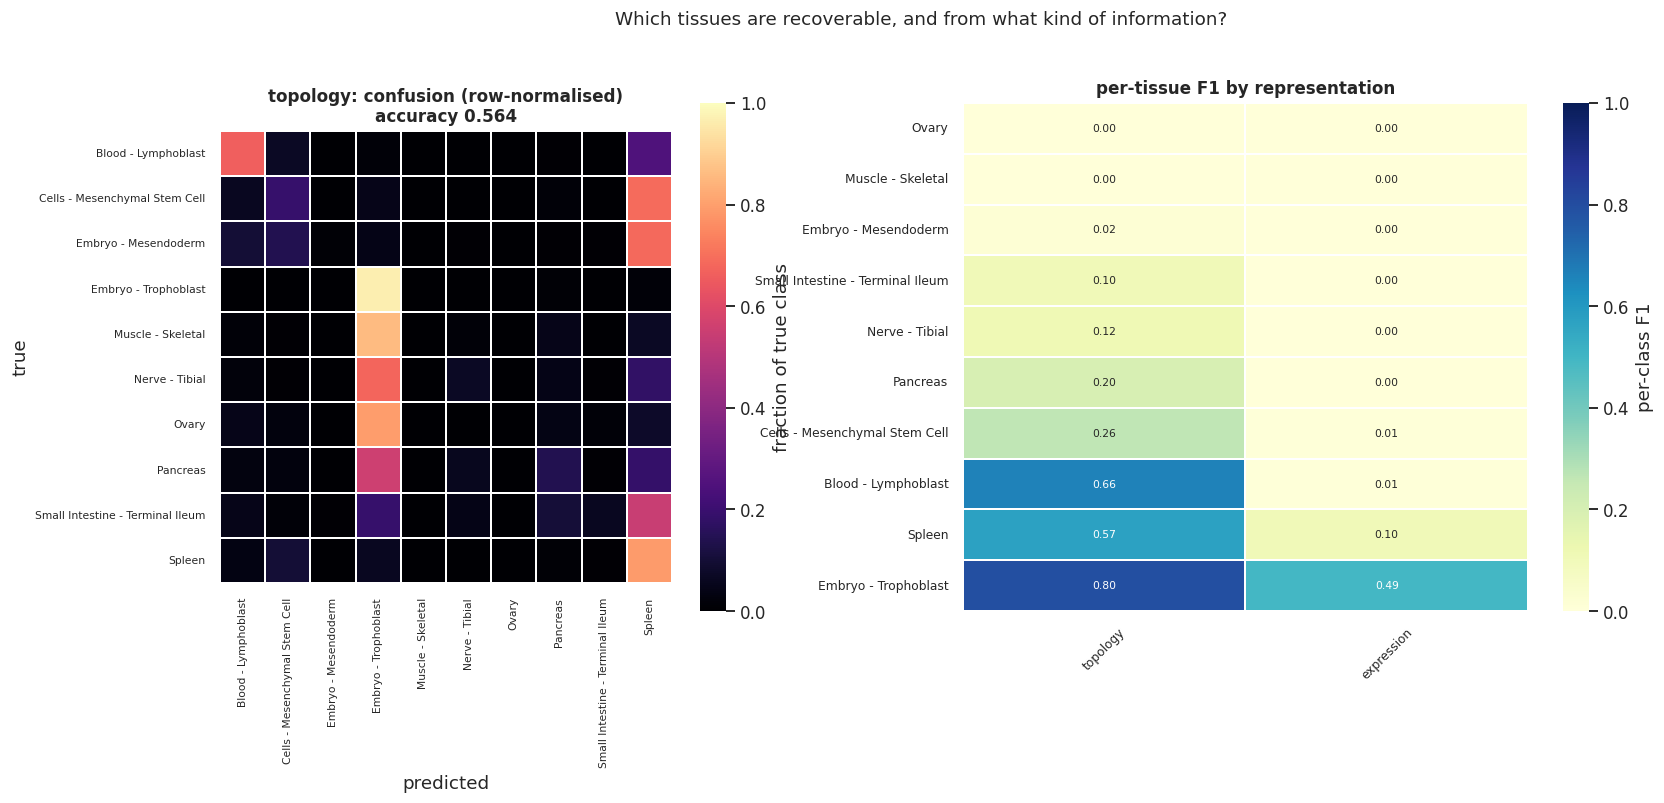


hardest tissues (mean F1): Ovary 0.00, Muscle - Skeletal 0.00, Embryo - Mesendoderm 0.01
easiest tissues (mean F1): Blood - Lymphoblast 0.33, Spleen 0.34, Embryo - Trophoblast 0.64

largest single confusion: Muscle - Skeletal -> Embryo - Trophoblast  (85.6% of Muscle - Skeletal rows)


In [16]:
if PERCLASS:
    d = PRB[PRB["class variable"] == "tissue"]
    bestrep = d.sort_values("F1 macro", ascending=False).iloc[0]["representation"]
    y, pred, classes = PERCLASS[bestrep]

    print(f"per-class report — {bestrep}\n")
    print(classification_report(y, pred, target_names=list(classes), zero_division=0))

    fig = plt.figure(figsize=(17, 6))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.25], wspace=.28)

    ax = fig.add_subplot(gs[0])
    cm = confusion_matrix(y, pred).astype(float)
    cmn = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    sns.heatmap(cmn, cmap="magma", vmin=0, vmax=1, ax=ax, square=True,
                xticklabels=classes, yticklabels=classes, linewidths=.3,
                linecolor="white", cbar_kws={"label": "fraction of true class"})
    ax.set_title(f"{bestrep}: confusion (row-normalised)\n"
                 f"accuracy {accuracy_score(y, pred):.3f}")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

    ax = fig.add_subplot(gs[1])
    grid = {}
    for name, (yy, pp, cc) in PERCLASS.items():
        _, _, f1, _ = precision_recall_fscore_support(yy, pp, average=None,
                                                      zero_division=0)
        grid[name] = pd.Series(f1, index=cc)
    G = pd.DataFrame(grid)
    G = G.reindex(G.mean(1).sort_values().index)
    sns.heatmap(G, cmap="YlGnBu", vmin=0, vmax=1, ax=ax, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=.3, linecolor="white",
                cbar_kws={"label": "per-class F1"})
    ax.set_title("per-tissue F1 by representation")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    fig.suptitle("Which tissues are recoverable, and from what kind of information?",
                 y=1.02, fontsize=12)
    savefig(fig, "eda_12_perclass_confusion"); plt.show()

    G.to_csv(EDA_DIR / "per_tissue_f1.csv")
    worst = G.mean(1).head(3); bestt = G.mean(1).tail(3)
    print(f"\nhardest tissues (mean F1): "
          + ", ".join(f"{k} {v:.2f}" for k, v in worst.items()))
    print(f"easiest tissues (mean F1): "
          + ", ".join(f"{k} {v:.2f}" for k, v in bestt.items()))
    off = cmn.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"\nlargest single confusion: {classes[i]} -> {classes[j]}  "
          f"({off[i, j]:.1%} of {classes[i]} rows)")
else:
    print("no per-class probe results")

## 17 · Summary and export

One table combining everything: for each representation, its dimensionality,
effective dimensionality, unsupervised agreement with tissue, model-free
separability, and linear decodability.

**How to read it.** The comparison that matters is `z`, `z_str` and `z_seq`
against `topology`, `histone` and `sequence`. The learned embeddings were
trained with the labels; the input representations were not. So the embeddings
*should* win on the supervised probe almost by construction. The honest question
is whether they win on the **unsupervised** columns — ARI, NMI, k-NN purity —
because that would mean the training reorganised the space rather than merely
carving a decision boundary through it.

If the embeddings beat the inputs on the probe but not on ARI, the model has
learned a classifier, not a representation. That is a perfectly good outcome for
prediction and a poor one if you intend to use the embedding for anything else.

SUMMARY — every representation, every diagnostic
               source  dims      PC1 %  PCs for 80%  effective dim  ARI (kmeans/tissue)  NMI (kmeans/tissue)  purity (kmeans/tissue)  kNN purity (tissue)  probe F1 (tissue)  kNN purity (expressed)  probe F1 (expressed)  kNN purity (tau class)  probe F1 (tau class)
representation                                                                                                                                                                                                                                                          
topology        input    19  25.799999            5            7.0                0.125                0.187                   0.444                0.422              0.272                   0.524                 0.512                   0.583                 0.415
expression      input    43  71.699997            3            4.2               -0.001                0.004                   0.325                0.187   

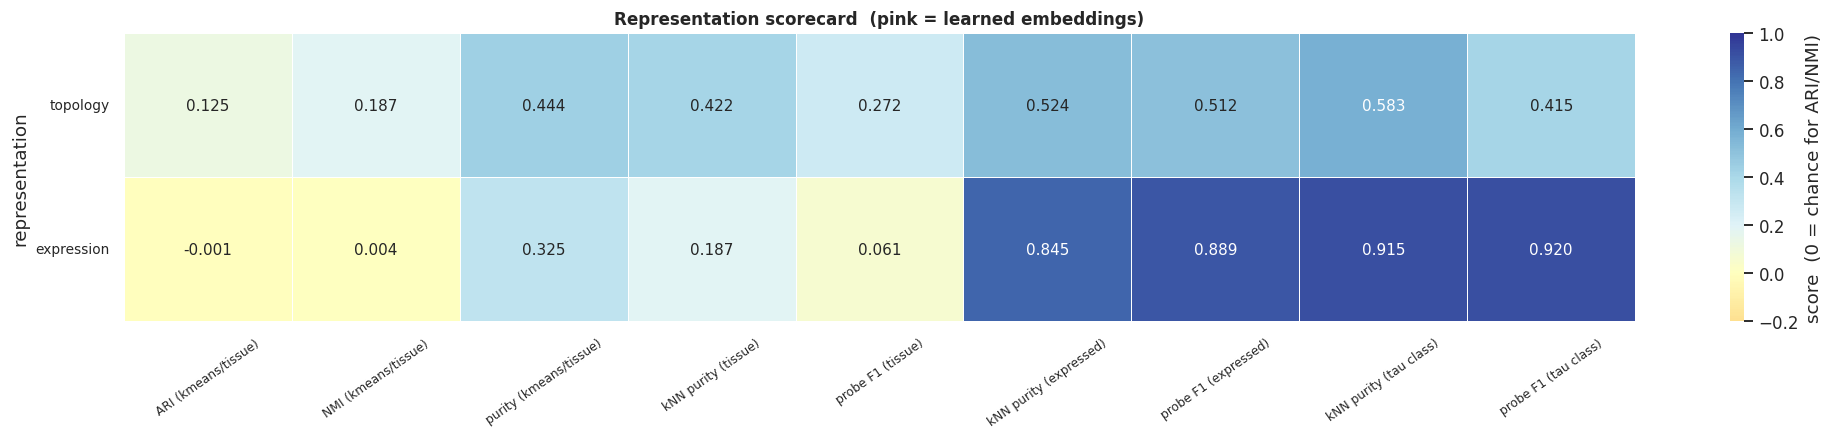


Automatic reading
  expression: kNN purity 0.19 -> essentially no tissue structure (expected for per-gene representations).

all tables -> results/eda/
  class_separability.csv
  clustering_vs_tissue.csv
  k_selection.csv
  linear_probe.csv
  pca_variance.csv
  per_tissue_f1.csv
  representations.csv
  summary_all.csv

figures (19):
  eda_01_labels.png
  eda_02_pca_scree.png
  eda_03_pca_loadings.png
  eda_04_pca_scatter_expression.png
  eda_04_pca_scatter_histone.png
  eda_04_pca_scatter_input_all.png
  eda_04_pca_scatter_topology.png
  eda_05_manifold_expression.png
  eda_05_manifold_histone.png
  eda_05_manifold_input_all.png
  eda_05_manifold_topology.png
  eda_06_k_selection.png
  eda_07_cluster_agreement.png
  eda_08_contingency.png
  eda_09_separability.png
  eda_10_per_class.png
  eda_11_probe.png
  eda_12_perclass_confusion.png
  eda_13_scorecard.png


In [17]:
parts = [VAR.set_index("representation")[["dims", "PC1 %", "PCs for 80%",
                                          "effective dim"]]]
if len(CL):
    kk = (CL[CL.algorithm.str.startswith("kmeans")]
            .set_index("representation")[["ARI", "NMI", "purity"]]
            .rename(columns=lambda c: f"{c} (kmeans/tissue)"))
    parts.append(kk)
for cname, _ in CLASS_VARS:
    s = SEPD[SEPD["class variable"] == cname].set_index("representation")
    if len(s):
        parts.append(s[["kNN purity"]].rename(
            columns={"kNN purity": f"kNN purity ({cname})"}))
    p_ = PRB[PRB["class variable"] == cname].set_index("representation")
    if len(p_):
        parts.append(p_[["F1 macro"]].rename(
            columns={"F1 macro": f"probe F1 ({cname})"}))

FINAL = pd.concat(parts, axis=1).reindex([n for n in names])
FINAL.insert(0, "source", ["learned" if n in ("z", "z_seq", "z_str") else "input"
                           for n in FINAL.index])
print("=" * 110)
print("SUMMARY — every representation, every diagnostic")
print("=" * 110)
print(FINAL.round(3).to_string())
FINAL.to_csv(EDA_DIR / "summary_all.csv")

num = FINAL.select_dtypes("number")
show = [c for c in num.columns if c not in ("dims", "PCs for 80%", "PC1 %",
                                            "effective dim")]
if show:
    fig, ax = plt.subplots(figsize=(1.5 * len(show) + 5, .55 * len(FINAL) + 3))
    # diverging scale centred on 0: ARI can be negative (worse than chance) and
    # a sequential map would render -0.01 and 0.00 identically
    sns.heatmap(num[show], annot=True, fmt=".3f", cmap="RdYlBu", center=0,
                vmin=-0.2, vmax=1, linewidths=.4, linecolor="white", ax=ax,
                cbar_kws={"label": "score  (0 = chance for ARI/NMI)"})
    for i, n in enumerate(FINAL.index):
        if n in ("z", "z_seq", "z_str"):
            ax.add_patch(plt.Rectangle((0, i), len(show), 1, fill=False,
                                       edgecolor="#D14A73", lw=2.2))
    ax.set_title("Representation scorecard  (pink = learned embeddings)")
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    fig.tight_layout(); savefig(fig, "eda_13_scorecard"); plt.show()

if HAS_EMB:
    learned = [n for n in ("z", "z_str", "z_seq") if n in FINAL.index]
    inputs = [n for n in FINAL.index if n not in learned]
    print("\n" + "=" * 70)
    print("Learned vs input, on the columns that were NOT optimised for")
    print("=" * 70)
    for col in [c for c in num.columns if "ARI" in c or "NMI" in c
                or "kNN purity" in c]:
        lv = num.loc[learned, col].dropna()
        iv = num.loc[inputs, col].dropna()
        if len(lv) and len(iv):
            print(f"  {col:<28} learned best {lv.max():.3f} "
                  f"({lv.idxmax()})   input best {iv.max():.3f} ({iv.idxmax()})"
                  f"   {'LEARNED WINS' if lv.max() > iv.max() else 'input wins'}")

# ---- automatic read of the most common informative pattern -----------------
print("\n" + "=" * 70)
print("Automatic reading")
print("=" * 70)
for rep in FINAL.index:
    ari = num.loc[rep].get("ARI (kmeans/tissue)", np.nan)
    knn = num.loc[rep].get("kNN purity (tissue)", np.nan)
    f1 = num.loc[rep].get("probe F1 (tissue)", np.nan)
    if not (np.isfinite(ari) and np.isfinite(knn)):
        continue
    if knn > 0.6 and ari < 0.1:
        print(f"  {rep}: kNN purity {knn:.2f} but ARI {ari:.3f} -> tissue classes")
        print("     are LOCALLY coherent but GLOBALLY interleaved. k-means assumes")
        print("     compact blobs and fails; a k-NN or tree model would not.")
    elif ari > 0.3:
        print(f"  {rep}: ARI {ari:.2f} -> tissue is a dominant axis of variance.")
    elif knn < 0.3:
        print(f"  {rep}: kNN purity {knn:.2f} -> essentially no tissue structure "
              "(expected for per-gene representations).")

print(f"\nall tables -> {EDA_DIR.relative_to(PROJECT_ROOT)}/")
for p in sorted(EDA_DIR.glob("*.csv")):
    print(f"  {p.name}")
print(f"\nfigures ({len(list(FIG_DIR.glob('*.png')))}):")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p.name}")

## 18 · Caveats

**Things that will make these plots lie to you.**

1. **UMAP and t-SNE distances are not distances.** Between-cluster gaps, cluster
   sizes and cluster shapes in those plots carry no information. Both algorithms
   produce convincing islands from Gaussian noise. Every claim in this notebook
   that matters is backed by a number, not by a picture.

2. **PC1 may be sequencing depth.** Section 8 warns when PC1 loads mainly on
   `degree`, `reads_sum` and `span`. If it does, tissue separation along PC1 is
   a library-size artefact. The fix is to quantile-normalise depth per tissue
   before building `topology`, which this notebook deliberately does *not* do,
   so that the artefact stays visible.

3. **`sequence` and `expression` are per-gene.** They are broadcast across a
   gene's tissues, so they *cannot* separate tissues — a near-zero tissue ARI
   for them is correct behaviour, not a failure. They are included as controls
   precisely to show what a floor looks like.

4. **The tau class is constant per gene.** Any representation that encodes gene
   identity scores well on it. The gene-grouped CV in the probe prevents
   train/test leakage but does not make the task harder than it is.

5. **Embeddings cover fewer rows.** They exist only for the last fold's test
   split, so their scores rest on a smaller and non-random subset — the fold was
   chosen by gene grouping, not at random. Compare them to input representations
   with that in mind, and check the `n` column.

6. **Cluster metrics depend on k.** ARI at k = n_tissues is not the same claim
   as ARI at the silhouette-optimal k. Both are in the tables; do not quote one
   as the other.

**Cheap things worth trying next:**

- Set `N_TISSUES = None` to use all 46. The tissue task gets much harder and the
  confusion matrix becomes far more informative about which biosamples are
  genuinely similar.
- Raise `KMER_K` to 5 or 6. If `sequence` improves substantially, composition
  carries more signal than 4-mers capture — and the Hyena tower has more to
  find than the current numbers suggest.
- Regress `degree` out of `topology` and re-run section 12. If the tissue ARI
  collapses, the clustering was depth.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score, normalized_mutual_info_score,
    silhouette_score
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

print("=" * 80)
print("FOLLOW-UP: Depth Regression Test")
print("=" * 80)
print("\nTesting whether 'topology' tissue clustering is driven by sequencing depth.\n")

# -----------------------------------------------------------------
# 1. Extract topology representation
# -----------------------------------------------------------------
if "topology" not in REPS:
    print("ERROR: 'topology' representation not found. Run sections 1-6 first.")
else:
    topo_data = REPS["topology"]
    X_topo = topo_data["X"]  # Already standardized
    topo_cols = topo_data["cols"]
    valid_mask = topo_data["valid"]

    # Subset to valid rows
    X = X_topo[valid_mask]
    Lsub = LAB.iloc[np.where(valid_mask)[0]]
    y_tissue = LabelEncoder().fit_transform(Lsub["tissue_class"])
    n_tissues = len(np.unique(y_tissue))

    print(f"Working with {len(X):,} valid (gene, tissue) rows")
    print(f"Topology features: {len(topo_cols)}")
    print(f"  Columns: {', '.join(topo_cols[:10])}{'...' if len(topo_cols) > 10 else ''}")

    # -----------------------------------------------------------------
    # 2. Identify depth-proxy features
    # -----------------------------------------------------------------
    # Features that encode sequencing depth rather than biology
    depth_features = ["degree", "reads_sum", "reads_mean", "reads_max", "score_sum", "span"]
    depth_indices = [i for i, c in enumerate(topo_cols) if c in depth_features]

    if not depth_indices:
        print("\nWARNING: No depth features found in topology. Check column names.")
        print(f"Available columns: {topo_cols}")
    else:
        print(f"\nDepth-proxy features to regress out ({len(depth_indices)}):")
        for idx in depth_indices:
            print(f"  - {topo_cols[idx]}")

        # -----------------------------------------------------------------
        # 3. Baseline clustering (before regression)
        # -----------------------------------------------------------------
        print("\n" + "-" * 80)
        print("BASELINE: Clustering on original topology")
        print("-" * 80)

        # Subsample for speed
        sub_indices = subsample(len(X), cap=min(N_SUBSAMPLE, 6000))
        X_sub = X[sub_indices, :min(20, X.shape[1])]
        y_sub = y_tissue[sub_indices]

        km_baseline = KMeans(n_clusters=n_tissues, n_init=10, random_state=SEED).fit(X_sub)
        labels_baseline = km_baseline.labels_

        ari_baseline = adjusted_rand_score(y_sub, labels_baseline)
        nmi_baseline = normalized_mutual_info_score(y_sub, labels_baseline)
        sil_baseline = silhouette_score(X_sub, labels_baseline)

        print(f"  ARI (tissue):        {ari_baseline:.3f}")
        print(f"  NMI (tissue):        {nmi_baseline:.3f}")
        print(f"  Silhouette:          {sil_baseline:.3f}")

        # -----------------------------------------------------------------
        # 4. Regress out depth proxies
        # -----------------------------------------------------------------
        print("\n" + "-" * 80)
        print("REGRESSION: Removing depth-proxy features")
        print("-" * 80)

        # For each non-depth feature, regress out the depth features
        non_depth_indices = [i for i in range(len(topo_cols)) if i not in depth_indices]

        print(f"Regressing {len(depth_indices)} depth features out of {len(non_depth_indices)} other features...")

        X_depth = X[:, depth_indices]  # Predictors
        X_residual = np.zeros((len(X), len(non_depth_indices)), dtype=np.float32)

        for i, feat_idx in enumerate(non_depth_indices):
            y_feat = X[:, feat_idx]
            # Fit linear regression: y_feat ~ X_depth
            reg = LinearRegression().fit(X_depth, y_feat)
            residual = y_feat - reg.predict(X_depth)
            X_residual[:, i] = residual

        # Re-standardize residuals
        X_residual = StandardScaler().fit_transform(X_residual)

        print(f"Residual representation shape: {X_residual.shape}")

        # -----------------------------------------------------------------
        # 5. Re-cluster on residuals
        # -----------------------------------------------------------------
        print("\n" + "-" * 80)
        print("POST-REGRESSION: Clustering on residual (depth-free) topology")
        print("-" * 80)

        X_res_sub = X_residual[sub_indices, :min(20, X_residual.shape[1])]

        km_residual = KMeans(n_clusters=n_tissues, n_init=10, random_state=SEED).fit(X_res_sub)
        labels_residual = km_residual.labels_

        ari_residual = adjusted_rand_score(y_sub, labels_residual)
        nmi_residual = normalized_mutual_info_score(y_sub, labels_residual)
        sil_residual = silhouette_score(X_res_sub, labels_residual)

        print(f"  ARI (tissue):        {ari_residual:.3f}")
        print(f"  NMI (tissue):        {nmi_residual:.3f}")
        print(f"  Silhouette:          {sil_residual:.3f}")

        # -----------------------------------------------------------------
        # 6. Interpret the results
        # -----------------------------------------------------------------
        print("\n" + "=" * 80)
        print("INTERPRETATION")
        print("=" * 80)

        ari_delta = ari_baseline - ari_residual
        nmi_delta = nmi_baseline - nmi_residual

        print(f"\nARI change:  {ari_baseline:.3f} → {ari_residual:.3f}  (Δ = {ari_delta:+.3f})")
        print(f"NMI change:  {nmi_baseline:.3f} → {nmi_residual:.3f}  (Δ = {nmi_delta:+.3f})")

        if abs(ari_delta) < 0.05:
            verdict = "✓ ROBUST: Tissue clustering survives depth regression."
            detail = (
                "The tissue structure is real biology, not a sequencing depth artifact.\n"
                "The clustering is driven by contact patterns, not library size."
            )
        elif ari_delta > 0.2:
            verdict = "⚠ DEPTH-DRIVEN: Tissue clustering collapses after removing depth."
            detail = (
                "The original clustering was mostly a batch effect (sequencing depth).\n"
                "Consider quantile-normalizing depth per tissue before building topology,\n"
                "or use only non-depth features (distance distributions, partner counts)."
            )
        else:
            verdict = "~ PARTIAL: Depth contributes, but biology remains."
            detail = (
                "Depth explains some of the clustering, but not all of it.\n"
                "The tissue structure has both biological and technical components."
            )

        print(f"\n{verdict}")
        print(f"\n{detail}")

        # -----------------------------------------------------------------
        # 7. Save results
        # -----------------------------------------------------------------
        depth_test = pd.DataFrame([
            {"representation": "topology (original)",
             "ARI": ari_baseline, "NMI": nmi_baseline, "silhouette": sil_baseline},
            {"representation": "topology (depth-regressed)",
             "ARI": ari_residual, "NMI": nmi_residual, "silhouette": sil_residual},
        ])

        out_path = EDA_DIR / "depth_regression_test.csv"
        depth_test.to_csv(out_path, index=False)
        print(f"\nResults saved to: {out_path.relative_to(PROJECT_ROOT)}")

        print("\n" + "=" * 80)
        print("Next steps if depth-driven:")
        print("  1. Quantile-normalize degree/reads_sum/span per tissue")
        print("  2. Rebuild TOPO with normalized depth features")
        print("  3. Re-run section 12 (clustering)")
        print("  4. Check if tissue ARI improves with true biological signal")
        print("=" * 80)

FOLLOW-UP: Depth Regression Test

Testing whether 'topology' tissue clustering is driven by sequencing depth.



NameError: name 'REPS' is not defined